# End to end: depth from a swept laser line with two event cameras (method C)

This notebook runs the full pipeline on one recording, step by step, from raw events to a depth image and a point
cloud. It uses the functions of `06_stripe_depth/stripe_depth_core.py`, the code behind the step 6 app, and opens
them up to show what each step does.

**Setup.** Two Prophesee EVK4 cameras (1280 × 720) form a horizontal stereo pair, with left = 00050496 (sync master)
and right = 00051788 (slave). The sync cable gives both cameras **one shared clock**. A line laser, swept by a
stepper motor, draws a near-vertical stripe that moves across the scene. Each pixel fires ON events when the stripe
reaches it and OFF events when it has passed.

**Example data.** `06_stripe_depth/recordings/rec_20261116_162206`: 6.7 s, six sweeps, and a scene with several
objects at different distances. Depth steps, laser shadows and occlusions test the method in ways a flat wall cannot.

**Pipeline** (one sweep = one pass of the stripe across the scene = one depth image):

| Step | What | Function (`stripe_depth_core`) | Section |
|---|---|---|---|
| 0 | Rectification: raw pixel → rectified (x, row), from the step 1 and 2 calibration | `load_rig`, `rig.lut` | 2 |
| 1 | Sweep segmentation: find the time interval of each sweep | `on_counts_per_ms`, `detect_sweeps` | 3 |
| 2 | Stripe arrival: first ON event per pixel, after a neighbour filter | `first_events`, `read_sweep` | 4 |
| 3 | Stripe speed and direction, matching window | `stripe_motion` | 4 |
| 4 | **Timestamp matching**: disparity of every left event | `local_fit`, `match_time` | 5 |
| 5 | Depth image: rasterise, robust aggregation, Z = f B / d | `rasterise`, `robust_aggregate` | 6 |
| 6 | Point cloud and files | `cloud_from_result`, `save_result` | 7 |

Section 8 runs all six sweeps and checks how well they agree. Section 9 summarises.

In [1]:
%matplotlib inline
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib.patches import Rectangle

ROOT = next(p for p in [Path.cwd().resolve()] + list(Path.cwd().resolve().parents) if (p / "06_stripe_depth").is_dir())
sys.path.insert(0, str(ROOT / "06_stripe_depth"))
import recorder_core as rc  # noqa: E402  Event file reader (also puts the step 1-3 folders on sys.path)
import stereo_core as sc  # noqa: E402  Step 2: stereo calibration
import stripe_depth_core as sd  # noqa: E402  Step 6: method C

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
CAM_COLORS = {"left": "tab:blue", "right": "tab:orange"}
W, H = 1280, 720

REC_DIR = ROOT / "06_stripe_depth" / "recordings" / "rec_20261116_162206"
OUT_DIR = ROOT / "05_experiments" / "output" / "end_to_end" / REC_DIR.name
OUT_DIR.mkdir(parents=True, exist_ok=True)


def md_table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


def img_axes(ax, title=""):
    ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.set_aspect("equal"); ax.grid(False)
    if title:
        ax.set_title(title, fontsize=9)

## 1. The recording

One HDF5 file per camera (written by the step 4/6 recorder): `x`, `y`, `p` (1 = ON, 0 = OFF) and `t` (µs) per
event, plus a 1 ms index for fast seeking. With hardware sync both files share one time base and cover the same
interval, so a timestamp means the same instant in both cameras.

In [2]:
session = json.loads((REC_DIR / "session.json").read_text())
files = rc.find_recording_files(REC_DIR)
readers = {role: rc.EventFileReader(f) for role, f in files.items()}
T0 = readers["left"].t_start

rows = []
for role, rd in readers.items():
    p_all = rd.ds["p"][:]
    quiet = rd.events_between(T0 + 500_000, T0 + 1_100_000)  # 0.6 s between two sweeps
    per_pix = np.bincount(quiet["y"].astype(np.int64) * W + quiet["x"], minlength=W * H)
    hot = np.where(per_pix > 1000)[0]
    rows.append([role, rd.serial, rd.attrs.get("sync_mode", ""), f"{rd.n / 1e6:.1f} M", f"{rd.duration_s:.2f} s",
                 f"{p_all.mean() * 100:.0f} %", len(hot),
                 f"{per_pix[hot].sum() / max(len(quiet['t']), 1) * 100:.0f} %" if len(hot) else "-"])
md_table(["Camera", "Serial", "Sync", "Events", "Duration", "ON share", "Hot pixels (> 1000 ev / 0.6 s)",
          "Hot pixels' share of events between sweeps"], rows)
print("same time base:", {r: (rd.t_start, rd.t_stop) for r, rd in readers.items()})

| Camera | Serial | Sync | Events | Duration | ON share | Hot pixels (> 1000 ev / 0.6 s) | Hot pixels' share of events between sweeps |
|---|---|---|---|---|---|---|---|
| left | 00050496 | master | 11.3 M | 6.72 s | 43 % | 0 | - |
| right | 00051788 | slave | 62.4 M | 6.72 s | 5 % | 2 | 98 % |

same time base: {'left': (572039998, 578759991), 'right': (572039998, 578759991)}


The right file is five times larger than the left one only because of **two hot pixels** that fire OFF events
continuously (millions per second). The pipeline uses ON events only, and the neighbour filter of section 4 would
reject isolated pixels anyway, so they need no special treatment.

## 2. Rectification (brief)

Rectification makes the stereo match one-dimensional. After it, a scene point appears on the **same row** in both
cameras, and its horizontal offset (the disparity d) gives the depth:

$$Z = \frac{f\,B}{d}, \qquad X = \frac{(x - c_x)\,Z}{f}, \qquad Y = \frac{(\text{row} - c_y)\,Z}{f}$$

* **Step 1** calibrated each camera's intrinsics: camera matrix K and lens distortion (strong barrel distortion,
  k1 ≈ −0.47).
* **Step 2** estimated the pose of the right camera relative to the left (R, T; baseline B = |T|). `cv2.stereoRectify`
  then gives the rotations R1, R2 and the new projection matrices P1, P2 that make the two image planes coplanar,
  with aligned rows.
* **For events**, there is no image to remap. Instead a look-up table holds, for every raw pixel (x, y), its rectified
  position: undistort, rotate by R1 or R2, project with P1 or P2 (`stereo_core.compute_event_lut`). An event is
  rectified with one look-up, `lut[y, x]`. x stays sub-pixel (it carries the disparity); the row is rounded.

The calibration is found by the two serial numbers, and each file gets the calibration side of its own serial. The
derivation is in `02_stereo_rectification/RECTIFICATION.md`.

In [3]:
STEREO_JSON = sc.find_stereo_file(ROOT / "02_stereo_rectification" / "output", readers["left"].serial,
                                  readers["right"].serial)
rig = sd.load_rig(STEREO_JSON)
side_of = {role: rig.side_of(rd.serial, role) for role, rd in readers.items()}
print("calibration:", Path(STEREO_JSON).name, "| calibration side per recording role:", side_of)
print(rig.describe())
fB = rig.f * rig.baseline
md_table(["Depth Z", "Disparity d = fB / Z", "Depth step per px of disparity, Z² / fB"],
         [[f"{z:.2f} m", f"{fB / z:.0f} px", f"{z * z / fB * 1e3:.1f} mm"] for z in (0.5, 0.6, 0.7, 0.8, 1.0)])

calibration: stereo_00050496_00051788.json | calibration side per recording role: {'left': 'left', 'right': 'right'}
f = 1689.6 px, baseline = 50.1 mm, 1280x720
Z = 84.7 / d (m): d = 100 px -> 0.847 m, 1 px of disparity there = 8.5 mm


| Depth Z | Disparity d = fB / Z | Depth step per px of disparity, Z² / fB |
|---|---|---|
| 0.50 m | 169 px | 3.0 mm |
| 0.60 m | 141 px | 4.3 mm |
| 0.70 m | 121 px | 5.8 mm |
| 0.80 m | 106 px | 7.6 mm |
| 1.00 m | 85 px | 11.8 mm |

Raw versus rectified events, both cameras overlaid: all ON events of the same 1 ms at mid-sweep. The stripe is where
the laser is during this millisecond.

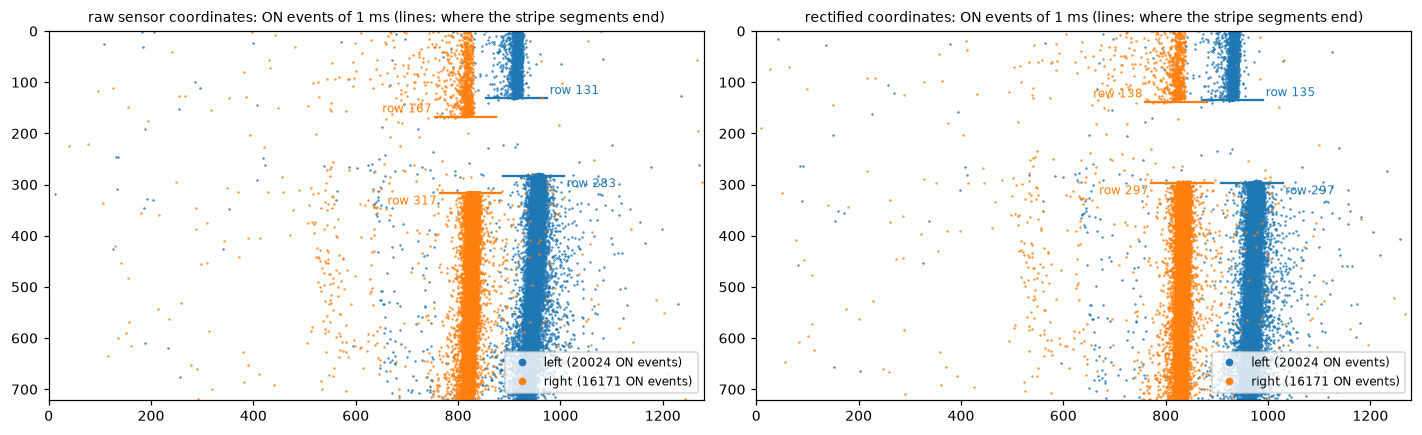

In [4]:
c_on = {role: sd.on_counts_per_ms(rd) for role, rd in readers.items()}  # ON events per 1 ms bin (used in section 3)
k_peak = int(np.argmax(c_on["left"][:1000]))  # A millisecond of the first sweep with the longest stripe
t_a, t_b = T0 + k_peak * 1000, T0 + (k_peak + 1) * 1000

def segment_ends(x, y, split=220):
    """Rows where the stripe's upper segment ends (bottom) and the lower segment starts (top)."""
    out = []
    for k, q in ((y < split, 99.5), (y >= split, 0.5)):
        mx = np.median(x[k])
        band = k & (np.abs(x - mx) < 25)
        out.append((mx, np.percentile(y[band], q)))
    return out


fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
for role, rd in readers.items():
    ev = rd.events_between(t_a, t_b)
    on = ev["p"] > 0
    x, y = ev["x"][on].astype(np.int64), ev["y"][on].astype(np.int64)
    xy = rig.lut[side_of[role]][y, x]
    for ax, (xx, yy) in zip(axs, ((x, y), (xy[:, 0], xy[:, 1]))):
        ax.plot(xx, yy, ".", ms=1, color=CAM_COLORS[role], label=f"{role} ({on.sum()} ON events)")
        for j, (mx, ry) in enumerate(segment_ends(xx, yy)):
            ax.plot([mx - 60, mx + 60], [ry, ry], "-", color=CAM_COLORS[role], lw=1.5)
            ax.text(mx + (65 if role == "left" else -65), ry + (-8 if j == 0 else 22), f"row {ry:.0f}", fontsize=8,
                    color=CAM_COLORS[role], ha="left" if role == "left" else "right")
for ax, title in zip(axs, ("raw sensor coordinates", "rectified coordinates")):
    img_axes(ax, f"{title}: ON events of 1 ms (lines: where the stripe segments end)")
    ax.legend(loc="lower right", markerscale=8, fontsize=8)
plt.tight_layout(); plt.show()

The stripe is broken in two: the gap between the upper and the lower segment is where the laser passes over a
depth step. In raw coordinates the segment ends of the two cameras sit on different rows, by more than 30 px (the
principal points differ, and the cameras are slightly rotated relative to each other). After rectification they are
on the same row, to within the few pixels to which these ends can be read off sparse events. That is the
property the matching relies on. In the rectified image the two
stripes are horizontally shifted copies, and the shift is the disparity.

## 3. Sweep segmentation

The stepper sweeps the laser across the scene, pauses, and sweeps back. During a sweep, the stripe makes the left
camera fire tens of thousands of ON events per millisecond, against ~50 between sweeps. `detect_sweeps` thresholds
the ON events per 1 ms bin of the left camera:

* threshold = median + 6 · σ_robust + 10, with σ_robust = 1.4826 · MAD (at least √median);
* active bins closer than 20 ms are merged, bursts shorter than 3 ms are dropped;
* each sweep is padded by 5 ms on both sides, so the stripe's first and last pixels are included.

It needs only the counts per ms, so it takes a fraction of a second for the whole file.

median 47 ON events/ms, robust sigma 22.2, threshold 190  ->  6 sweeps


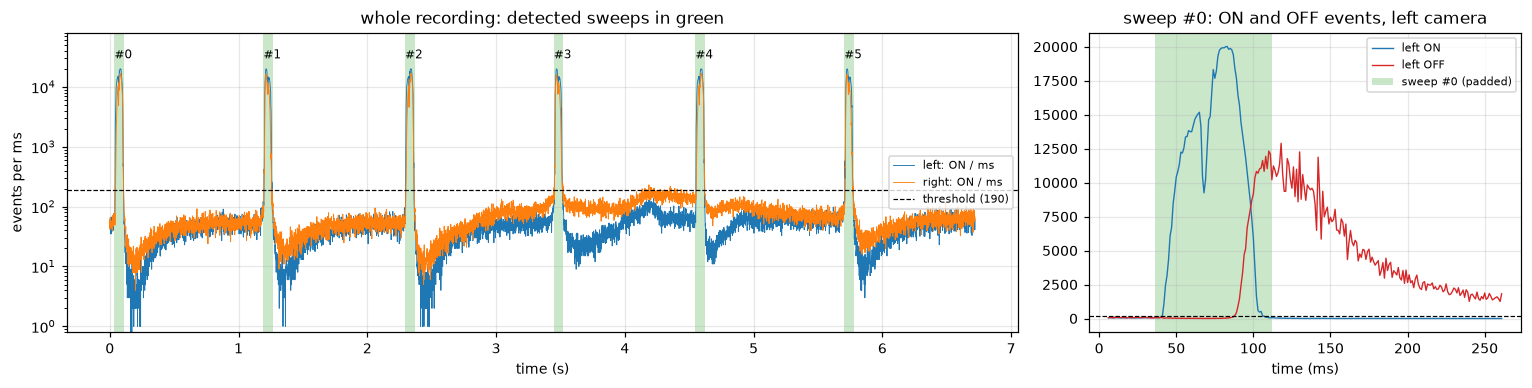

| Sweep | Start (s) | Duration (ms, padded) |
|---|---|---|
| #0 | 0.036 | 76 |
| #1 | 1.193 | 72 |
| #2 | 2.293 | 74 |
| #3 | 3.448 | 73 |
| #4 | 4.548 | 76 |
| #5 | 5.704 | 73 |

In [5]:
sp = sd.SweepParams()
sweeps = sd.detect_sweeps(c_on["left"], T0, sp)
c = c_on["left"].astype(float)
med = np.median(c)
sigma = max(1.4826 * np.median(np.abs(c - med)), np.sqrt(max(med, 1.0)))
thr = med + sp.n_sigma * sigma + 10
print(f"median {med:.0f} ON events/ms, robust sigma {sigma:.1f}, threshold {thr:.0f}  ->  {len(sweeps)} sweeps")

fig, axs = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
t_ms = np.arange(c.size)
for role in readers:
    axs[0].plot(t_ms / 1e3, np.maximum(c_on[role], 0.8), lw=0.6, color=CAM_COLORS[role], label=f"{role}: ON / ms")
axs[0].axhline(thr, color="k", ls="--", lw=0.8, label=f"threshold ({thr:.0f})")
for k, (a, b) in enumerate(sweeps):
    axs[0].axvspan((a - T0) / 1e6, (b - T0) / 1e6, color="tab:green", alpha=0.25, lw=0)
    axs[0].text((a - T0) / 1e6, 3e4, f"#{k}", fontsize=8)
axs[0].set_yscale("log"); axs[0].set_ylim(0.8, 8e4); axs[0].set_xlabel("time (s)"); axs[0].set_ylabel("events per ms")
axs[0].set_title("whole recording: detected sweeps in green"); axs[0].legend(fontsize=7, loc="center right")

# Zoom on sweep 0: ON and OFF events of the left camera
a, b = sweeps[0]
ev = readers["left"].events_between(a - 30_000, b + 150_000)
k = (ev["t"] - (a - 30_000)) // 1000
tz = (a - 30_000 - T0) / 1e3 + np.arange(k.max() + 1)
axs[1].plot(tz, np.bincount(k[ev["p"] > 0], minlength=k.max() + 1), color="tab:blue", lw=0.9, label="left ON")
axs[1].plot(tz, np.bincount(k[ev["p"] == 0], minlength=k.max() + 1), color="tab:red", lw=0.9, label="left OFF")
axs[1].axhline(thr, color="k", ls="--", lw=0.8)
axs[1].axvspan((a - T0) / 1e3, (b - T0) / 1e3, color="tab:green", alpha=0.25, lw=0, label="sweep #0 (padded)")
axs[1].set_xlabel("time (ms)"); axs[1].set_title("sweep #0: ON and OFF events, left camera")
axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

md_table(["Sweep", "Start (s)", "Duration (ms, padded)"],
         [[f"#{k}", f"{(a - T0) / 1e6:.3f}", f"{(b - a) / 1e3:.0f}"] for k, (a, b) in enumerate(sweeps)])

Six sweeps of ~73 ms, one every ~1.1 s (the stepper pauses in between). **Only ON events are counted.** OFF events
fire when the stripe has passed and the pixel darkens again; they trail the ON burst by tens of ms (red curve) and
would split each sweep into two bursts or stretch it. The background rate also changes after each sweep (pixels
recovering), which is why the threshold uses robust statistics of the whole file.

## 4. Stripe arrival time per pixel

Within a sweep the stripe passes each lit pixel once, so **one number per pixel** describes the sweep: the time the
stripe reached it. It is taken as the pixel's **first ON event** in the sweep. Two problems:

* a pixel fires several ON events while the stripe crosses it; only the first marks the arrival;
* background activity and scattered laser light make pixels fire **before** the stripe arrives. If such an event is
  the pixel's first, it replaces the true arrival time.

**Neighbour filter.** The stripe is a continuous line, so when it reaches a pixel, the neighbouring pixels along the
line fire at nearly the same time. A noise event is isolated. An event is kept only if ≥ 2 of its 8 neighbours fired
within ±300 µs (counting all ON events). `first_events` walks each pixel's events in time order and keeps the first
one that passes. The filter works on the raw sensor grid, so the kept events are rectified afterwards.

The plot shows one raw sensor row of sweep #0: every ON event, the first ON event per pixel without the filter, and
the one with it.

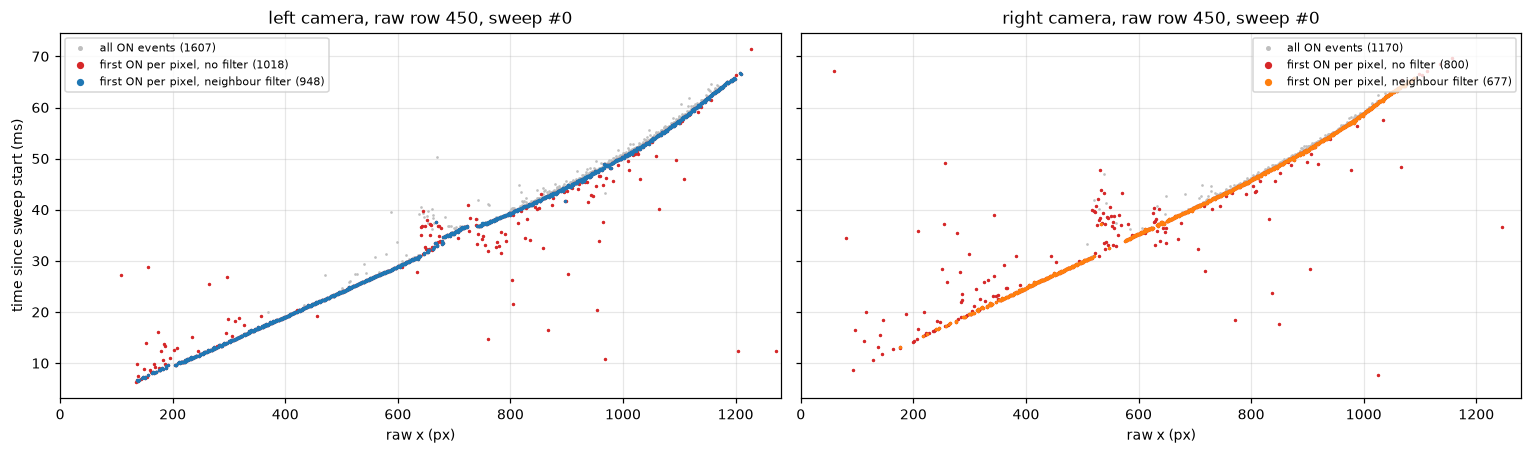

In [6]:
dp = sd.DepthParams()
SW = 0
t0, t1 = sweeps[SW]


def sweep_detail(rd, t0, t1, p):
    """All ON events of a sweep, time-sorted, with the first event per pixel without and with the neighbour filter."""
    ev = rd.events_between(t0, t1)
    on = ev["p"] > 0
    t, x, y = ev["t"][on].astype(np.int64), ev["x"][on].astype(np.int64), ev["y"][on].astype(np.int64)
    o = np.argsort(t, kind="stable")
    t, x, y = t[o], x[o], y[o]
    pix = y * rd.width + x
    first_raw = np.sort(np.unique(pix, return_index=True)[1])  # First ON event of every pixel, no filter
    first = sd.first_events(pix, t, rd.width, rd.height, p.nb_delta_us, p.nb_min)  # With the neighbour filter
    return {"t": t, "x": x, "y": y, "first_raw": first_raw, "first": first}


det = {side_of[role]: sweep_detail(rd, t0, t1, dp) for role, rd in readers.items()}
ROW_RAW = 450
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, side in zip(axs, ("left", "right")):
    D = det[side]
    k_all = D["y"] == ROW_RAW
    ax.plot(D["x"][k_all], (D["t"][k_all] - t0) / 1e3, ".", ms=1.5, color="0.75", label=f"all ON events ({k_all.sum()})")
    for key, col, lab in (("first_raw", "tab:red", "first ON per pixel, no filter"),
                          ("first", CAM_COLORS[side], "first ON per pixel, neighbour filter")):
        i = D[key][D["y"][D[key]] == ROW_RAW]
        ax.plot(D["x"][i], (D["t"][i] - t0) / 1e3, ".", ms=2.5, color=col, label=f"{lab} ({i.size})")
    ax.set_title(f"{side} camera, raw row {ROW_RAW}, sweep #{SW}"); ax.set_xlabel("raw x (px)"); ax.set_xlim(0, W)
    ax.legend(fontsize=7, markerscale=3, loc="upper left" if side == "left" else "upper right")
axs[0].set_ylabel("time since sweep start (ms)")
plt.tight_layout(); plt.show()

The stripe is the diagonal band: it moves along the row, and each pixel fires a short burst as it passes. Without
the filter, many pixels' first event lies off the band (red dots): before the stripe arrives (background activity),
or, in pixels the stripe never reached, a random later event. Those pixels would get a wrong arrival time and later
a wrong disparity. The filter keeps the leading edge of the band and drops the rest. Where the band breaks, the row
crosses an object edge: the stripe jumps to another surface, or there is no stripe for a while (laser shadow,
occlusion, or a dark surface).

Event counts of sweep #0 through the steps (`read_sweep` does all of them; the last column is checked against it):

In [7]:
ev_sw = {}
rows = []
for role, rd in readers.items():
    side = side_of[role]
    ev_sw[side] = sd.read_sweep(rd, t0, t1, rig.lut[side], dp)
    D = det[side]
    rows.append([side, f"{D['t'].size:,}", f"{D['first_raw'].size:,}", f"{D['first'].size:,}",
                 f"{ev_sw[side].t.size:,}", "yes" if ev_sw[side].n_first == D["first"].size else "NO"])
md_table(["Camera", "ON events in the sweep", "Pixels with an ON event", "Pixels kept by the neighbour filter",
          "Inside the rectified image", "Same as read_sweep"], rows)

| Camera | ON events in the sweep | Pixels with an ON event | Pixels kept by the neighbour filter | Inside the rectified image | Same as read_sweep |
|---|---|---|---|---|---|
| left | 799,146 | 546,265 | 480,284 | 446,248 | yes |
| right | 525,637 | 378,036 | 298,352 | 293,315 | yes |

### The arrival-time maps

Each kept event is drawn at its rectified pixel, coloured by its time. In these maps a line of equal time (an
isochrone) is the stripe at that instant.

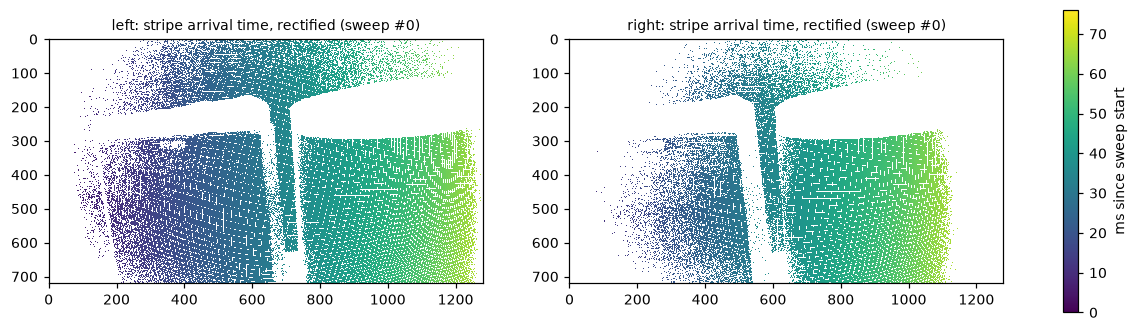

In [8]:
arr = {s: sd.rasterise(e.row, e.x, (e.t - t0) / 1e3, W, H) for s, e in ev_sw.items()}
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, side in zip(axs, ("left", "right")):
    im = ax.imshow(arr[side], cmap="viridis", vmin=0, vmax=(t1 - t0) / 1e3, interpolation="nearest")
    img_axes(ax, f"{side}: stripe arrival time, rectified (sweep #{SW})")
plt.colorbar(im, ax=axs, shrink=0.85, label="ms since sweep start")
plt.show()

The scene: a flat board on the left, a curved object on the right (both ~0.6–0.7 m), and a T-shaped object behind
them (~0.8 m) with its stem visible between the two. The thin white grid lines are rectified pixels that no raw
pixel maps onto: rectification magnifies the image slightly (rectified f = 1690 px against ~1630 px raw, and more
towards the edges, where the barrel distortion is undone). Section 6 fills them. White areas are not lit by the
laser, are too dark, or lie in a shadow. The right camera's map is sparse over the left part of the scene: it
receives a weaker stripe there. Section 5 shows the consequence.

**Stripe snapshots.** The kept events within ±0.15 ms of four instants: left camera solid, right camera faded. At
one instant both cameras see the same physical stripe. On each row, the right stripe is the left stripe shifted to
the left by the disparity (arrows), and the shift changes from object to object.

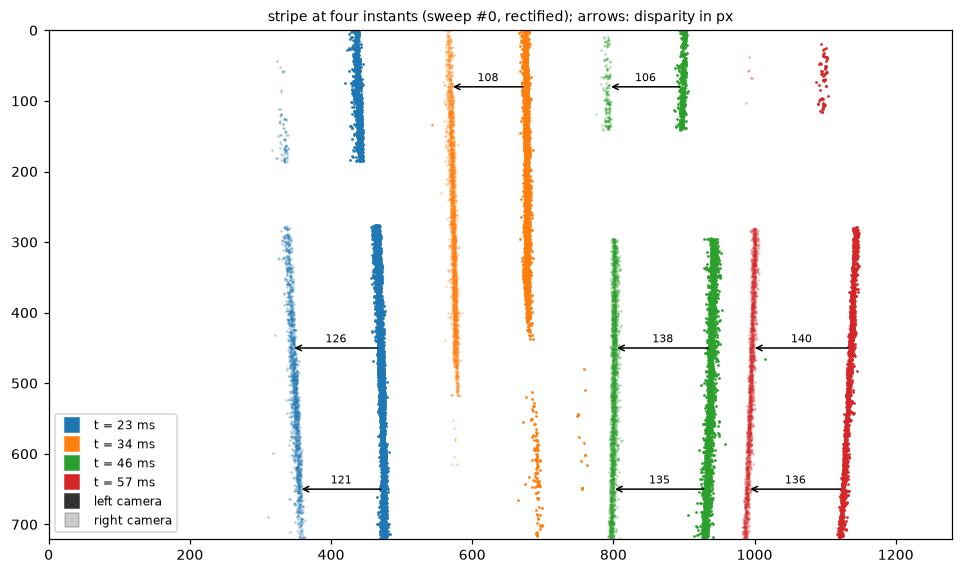

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))
dur = (t1 - t0) / 1e3
inst = [0.3, 0.45, 0.6, 0.75]
cols = plt.cm.tab10(np.arange(len(inst)))
for f_, col in zip(inst, cols):
    tk = t0 + f_ * dur * 1e3
    sel = {}
    for side, alpha in (("left", 1.0), ("right", 0.25)):
        e = ev_sw[side]
        k = np.abs(e.t - tk) <= 150
        sel[side] = k
        ax.plot(e.x[k], e.row[k], ".", ms=1.6, color=col, alpha=alpha)
    for r_arrow in (80, 450, 650):  # Disparity arrows where both cameras have the stripe on this row
        xs_ = []
        for side in ("left", "right"):
            e = ev_sw[side]
            kk = sel[side] & (np.abs(e.row - r_arrow) <= 3)
            xs_.append(np.median(e.x[kk]) if kk.sum() >= 5 else np.nan)
        if np.isfinite(xs_).all() and 40 < xs_[0] - xs_[1] < 250:
            ax.annotate("", (xs_[1], r_arrow), (xs_[0], r_arrow), arrowprops=dict(arrowstyle="->", color="k", lw=1))
            ax.text((xs_[0] + xs_[1]) / 2, r_arrow - 8, f"{xs_[0] - xs_[1]:.0f}", ha="center", fontsize=7)
    ax.plot([], [], "s", color=col, label=f"t = {f_ * dur:.0f} ms")
ax.plot([], [], "s", color="0.2", label="left camera"); ax.plot([], [], "s", color="0.2", alpha=0.25, label="right camera")
img_axes(ax, f"stripe at four instants (sweep #{SW}, rectified); arrows: disparity in px")
ax.legend(fontsize=8, markerscale=1.5, loc="lower left")
plt.show()

### Stripe speed and direction

The matching window of section 5 is defined in pixels of stripe motion and converted to time with the stripe speed.
`stripe_motion` takes the median x of the left camera's kept events in 0.5 ms bins and the median of the
bin-to-bin velocities. The median is robust to the object edges, where the stripe jumps.

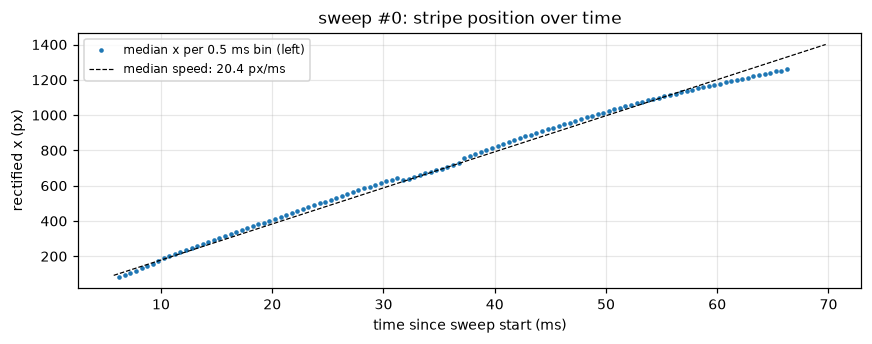

direction +x (left to right), speed 20.4 px/ms -> crosses 1280 px in 63 ms; matching window tau = 8 px = 391 us


In [10]:
e = ev_sw["left"]
b_ = (e.t - e.t[0]) // 500
cnt = np.bincount(b_)
med_x = np.array([np.median(e.x[b_ == i]) if cnt[i] >= 50 else np.nan for i in range(cnt.size)])
tc = (np.arange(cnt.size) + 0.5) * 0.5 + (e.t[0] - t0) / 1e3
direction, speed = sd.stripe_motion(e)
tau_us = dp.tau_px / speed * 1e3
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(tc, med_x, ".", ms=4, label="median x per 0.5 ms bin (left)")
mid = np.nanmedian(tc[np.isfinite(med_x)])
ax.plot(tc, np.nanmedian(med_x[np.isfinite(med_x)]) + direction * speed * (tc - mid), "k--", lw=0.8,
        label=f"median speed: {speed:.1f} px/ms")
ax.set_xlabel("time since sweep start (ms)"); ax.set_ylabel("rectified x (px)"); ax.legend(fontsize=8)
ax.set_title(f"sweep #{SW}: stripe position over time")
plt.tight_layout(); plt.show()
print(f"direction {'+x (left to right)' if direction > 0 else '-x (right to left)'}, speed {speed:.1f} px/ms "
      f"-> crosses {W} px in {W / speed:.0f} ms; matching window tau = {dp.tau_px:.0f} px = {tau_us:.0f} us")

## 5. Timestamp matching (method C)

### 5.1 Principle

Take a left event: pixel (x_L, row), time t. Three facts locate its 3D point:

1. it lies on the **ray** of the left pixel;
2. it lies in the **epipolar plane of its row**. After rectification, this plane projects to the same row in both
   cameras;
3. it lies in the **laser plane at time t**. The stripe is the laser plane hitting the scene, and the plane rotates
   with the stepper, so the time selects one plane.

The laser plane at time t and the epipolar plane of the row intersect in a single 3D line. Along it, the laser lights
exactly one point, the first surface it hits. The right camera sees that same point **on the same row, at the same
instant t**, because the shared clock gives both cameras the same t. So the right match is *where the right camera's
stripe is on this row at time t*: x_R(row, t). The disparity is d = x_L − x_R.

Ordinary stereo searches a row for the most similar patch, which fails on textureless surfaces and repeated
patterns. Here the timestamp alone picks the match: no appearance comparison, no search along the row, and the
result is unique. The plot shows it in the plane of one row, seen from above: everything in one picture lies in one
epipolar plane, and the laser plane appears as a line.

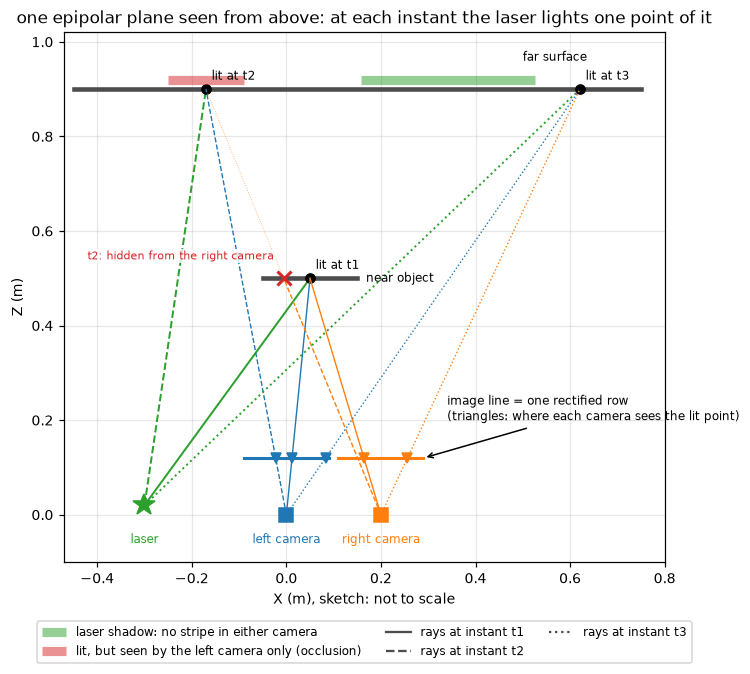

In [11]:
def ray_hit(o, ang, segs):
    """First hit of the ray from o at angle ang (from +Z, towards +X) with line segments [(p, q)]."""
    dvec = np.array([np.sin(ang), np.cos(ang)])
    best = None
    for p, q in segs:
        p, q = np.asarray(p, float), np.asarray(q, float)
        m = np.array([dvec, p - q]).T
        if abs(np.linalg.det(m)) < 1e-12:
            continue
        s, u = np.linalg.solve(m, p - o)
        if s > 1e-9 and 0 <= u <= 1 and (best is None or s < best[0]):
            best = (s, o + s * dvec)
    return best[1]


def seg_cross(o, p, seg):
    """Point where the segment o -> p crosses the line segment seg, or None."""
    q0, q1 = np.asarray(seg[0], float), np.asarray(seg[1], float)
    m = np.array([p - o, q0 - q1]).T
    if abs(np.linalg.det(m)) < 1e-12:
        return None
    s, u = np.linalg.solve(m, q0 - o)
    return o + s * (p - o) if (1e-9 < s < 1 - 1e-9 and 0 <= u <= 1) else None


B_s, f_s, Z_FAR = 0.2, 0.12, 0.9  # Sketch geometry (baseline exaggerated)
camL, camR, laser = np.array([0.0, 0.0]), np.array([B_s, 0.0]), np.array([-0.3, 0.02])
wall = ((-0.45, Z_FAR), (0.75, Z_FAR))
box = ((-0.05, 0.5), (0.15, 0.5))
fig, ax = plt.subplots(figsize=(11, 6.2))
ax.plot(*np.array(wall).T, color="0.3", lw=3); ax.text(0.5, Z_FAR + 0.06, "far surface", fontsize=8)
ax.plot(*np.array(box).T, color="0.3", lw=3); ax.text(0.16, 0.5, " near object", fontsize=8, va="center")
for cname, cpos, col in (("left camera", camL, CAM_COLORS["left"]), ("right camera", camR, CAM_COLORS["right"])):
    ax.plot(*cpos, "s", color=col, ms=9)
    ax.plot([cpos[0] - 0.09, cpos[0] + 0.09], [f_s, f_s], color=col, lw=2)
    ax.text(cpos[0], -0.06, cname, ha="center", fontsize=8, color=col)
ax.plot(*laser, "*", color="tab:green", ms=15); ax.text(laser[0], -0.06, "laser", ha="center", fontsize=8,
                                                         color="tab:green")
cases = [(np.radians(36.1), "t1", "-"), (np.radians(8.4), "t2", "--"), (np.radians(46.3), "t3", ":")]
for ang, tl, ls in cases:
    P = ray_hit(laser, ang, [wall, box])
    ax.plot([laser[0], P[0]], [laser[1], P[1]], ls, color="tab:green", lw=1.3)
    ax.plot(*P, "o", color="k", ms=6); ax.text(P[0] + 0.012, P[1] + 0.02, f"lit at {tl}", fontsize=8)
    for cpos, col in ((camL, CAM_COLORS["left"]), (camR, CAM_COLORS["right"])):
        blk = seg_cross(cpos, P, box)
        if blk is None:
            ax.plot([cpos[0], P[0]], [cpos[1], P[1]], ls, color=col, lw=0.9)
            xi = cpos[0] + (P[0] - cpos[0]) * f_s / P[1]
            ax.plot(xi, f_s, "v", color=col, ms=6)
        else:  # The near object hides the lit point from this camera
            ax.plot([cpos[0], blk[0]], [cpos[1], blk[1]], ls, color=col, lw=0.9)
            ax.plot([blk[0], P[0]], [blk[1], P[1]], ":", color=col, lw=0.6, alpha=0.6)
            ax.plot(*blk, "x", color="tab:red", ms=9, mew=2)
            ax.text(blk[0] - 0.02, blk[1] + 0.04, f"{tl}: hidden from the {('left' if cpos is camL else 'right')} camera",
                    fontsize=7, color="tab:red", ha="right", bbox=dict(fc="w", ec="none", alpha=0.8, pad=1))


def wall_hit(src, pnt):
    v = np.asarray(pnt, float) - src
    return src[0] + v[0] * (Z_FAR - src[1]) / v[1]


shadow = sorted(wall_hit(laser, p_) for p_ in box)
hidden_r = sorted(wall_hit(camR, p_) for p_ in box)
hidden_l = sorted(wall_hit(camL, p_) for p_ in box)
only_left = (hidden_r[0], min(hidden_r[1], hidden_l[0]))  # Lit and seen by the left camera only
ax.plot(shadow, [Z_FAR + 0.02] * 2, color="tab:green", lw=6, alpha=0.5, solid_capstyle="butt",
        label="laser shadow: no stripe in either camera")
ax.plot(only_left, [Z_FAR + 0.02] * 2, color="tab:red", lw=6, alpha=0.5, solid_capstyle="butt",
        label="lit, but seen by the left camera only (occlusion)")
ax.annotate("image line = one rectified row\n(triangles: where each camera sees the lit point)",
            (camR[0] + 0.09, f_s), (0.34, 0.2), fontsize=8, arrowprops=dict(arrowstyle="->"))
for tl, ls in (("t1", "-"), ("t2", "--"), ("t3", ":")):
    ax.plot([], [], ls, color="0.3", label=f"rays at instant {tl}")
ax.set_xlim(-0.47, 0.8); ax.set_ylim(-0.1, 1.02); ax.set_aspect("equal")
ax.set_xlabel("X (m), sketch: not to scale"); ax.set_ylabel("Z (m)")
ax.set_title("one epipolar plane seen from above: at each instant the laser lights one point of it")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

* **t1**: the laser hits the near object. Both cameras see the lit point, with a large disparity: the offset between
  the left (blue) and the right (orange) image positions.
* **t3**: the laser hits the far surface. Both cameras see it, with a smaller disparity.
* **t2**: the laser hits the far surface just beside the near object, where the object hides it from the right
  camera. The left camera fires, but at that instant the right camera has no stripe on this row: **occlusion**, no
  match. In the left image these areas lie just beside near objects.
* **Laser shadow** (green): the far surface behind the near object gets no light. Neither camera fires; there is no
  data, but also nothing to mismatch.

### 5.2 Finding x_R(row, t): a local line fit

The right camera has no event at exactly (row, t). Its kept events are discrete (one per pixel, the stripe moves
one pixel every ~50 µs here), and each one places the stripe only to ~2–3 px (where a pixel fires within the stripe's
brightness profile varies). So x_R(t) is estimated from the right events nearby:

* rows row − h … row + h (h = 1), times |t_R − t| ≤ τ, with τ = 8 px of stripe motion, i.e. ±8 px of stripe. The
  time window is fixed per sweep (τ = 8 px / median speed), so where the stripe moves faster or slower than the
  median, it covers somewhat more or fewer pixels;
* least-squares line x = a + b · (t_R − t). Because the line is centred on t, **a is the stripe position at time t**
  and b is the stripe speed;
* d = x_L − a.

The line follows the stripe's motion, so it uses events before and after t without bias. With u = t_R − t and sums
over the window:

$$a = \frac{\sum x \sum u^2 - \sum u \sum u x}{n \sum u^2 - (\sum u)^2}$$

Below: one rectified row of sweep #0, time against x, for the left events (row) and the right events (rows ± 1).

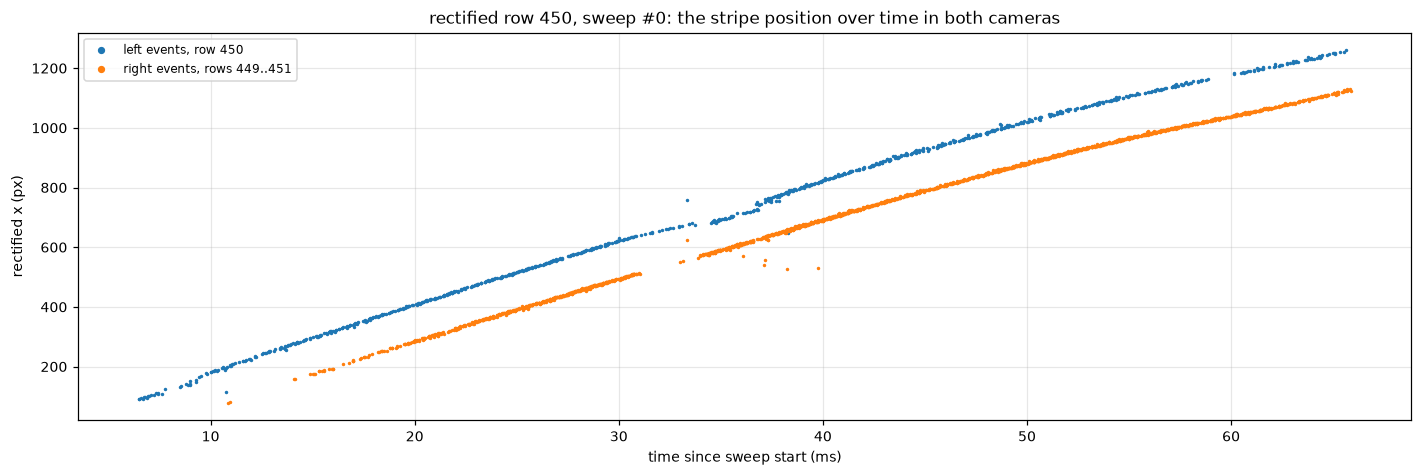

In [12]:
L, R = ev_sw["left"], ev_sw["right"]
t_ref = min(L.t[0], R.t[0])
a_fit, n_fit, ok_fit = sd.local_fit(L.t - t_ref, L.row, R.t - t_ref, R.x, R.row, tau_us, dp.row_halfwidth,
                                    dp.min_events)
d_all = L.x - a_fit
in_range = np.isfinite(d_all) & (d_all >= dp.d_min) & (d_all <= dp.d_max)
status = np.where(n_fit < dp.min_events, 1, np.where(~ok_fit, 2, np.where(~in_range, 3, 0)))
matched = status == 0

ROW = 450
kL = L.row == ROW
kR = np.abs(R.row - ROW) <= dp.row_halfwidth
fig, ax = plt.subplots(figsize=(13, 4.4))
ax.plot((L.t[kL] - t0) / 1e3, L.x[kL], ".", ms=2.5, color=CAM_COLORS["left"], label=f"left events, row {ROW}")
ax.plot((R.t[kR] - t0) / 1e3, R.x[kR], ".", ms=2.5, color=CAM_COLORS["right"],
        label=f"right events, rows {ROW - 1}..{ROW + 1}")
ax.set_xlabel("time since sweep start (ms)"); ax.set_ylabel("rectified x (px)")
ax.set_title(f"rectified row {ROW}, sweep #{SW}: the stripe position over time in both cameras")
ax.legend(fontsize=8, markerscale=3)
plt.tight_layout(); plt.show()

Each camera's stripe is a line of slope ≈ stripe speed. At any time, the right camera's line lies **below** the left
one by the disparity: the vertical distance between the two lines at the same time. The jumps are object edges:
the stripe moves onto a surface at another depth, so x jumps, and the jump is larger in one camera than in the
other because the disparity changes. Gaps are times when the stripe is not visible on this row.

**One match, zoomed in.** A left event on the left object, the right events in its window (rows ± 1, |t_R − t| ≤ τ),
the fitted line, and the resulting disparity. The fit is repeated here with `np.polyfit` and compared with the
vectorised `local_fit`.

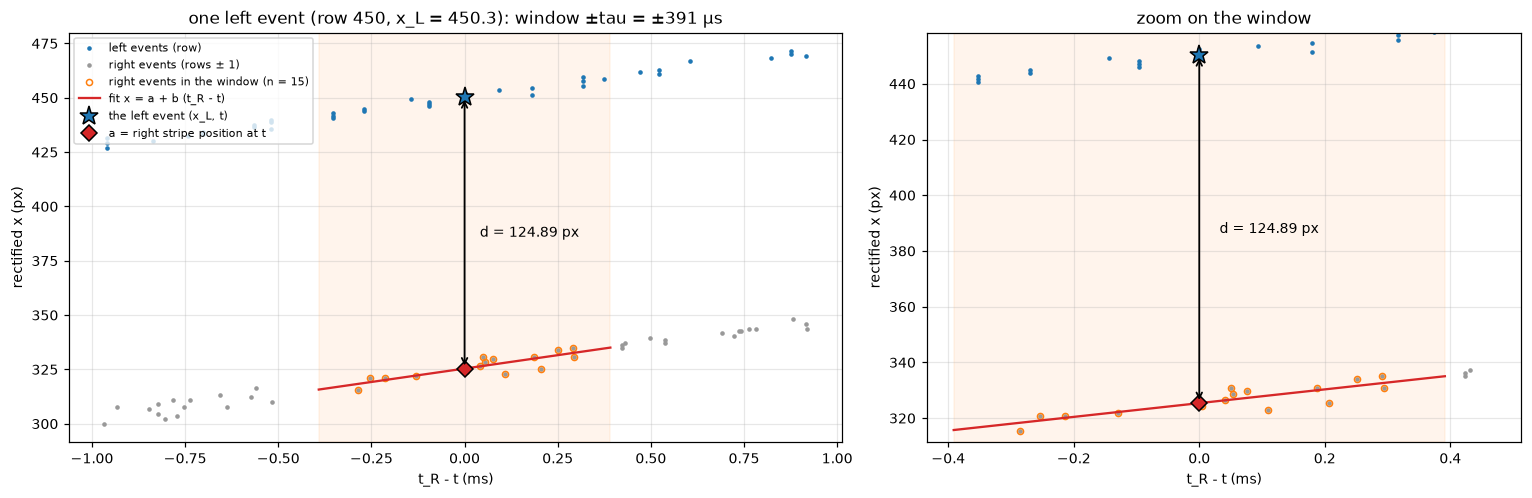

np.polyfit: a = 325.400 px, b = 24.67 px/ms  |  local_fit: a = 325.400 px, n = 15  ->  d = 124.888 px, Z = 678.2 mm
right events per window over all matched left events: median 31, 10-90 % 11-43


In [13]:
cand = np.where(kL & matched & (np.abs(L.x - 450) < 30))[0]
iq = cand[np.argmin(np.abs(L.x[cand] - 450))]
tq, xq = L.t[iq], L.x[iq]
win = kR & (np.abs(R.t - tq) <= tau_us)
u = (R.t[win] - tq).astype(float)
b_lin, a_lin = np.polyfit(u, R.x[win], 1)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
for ax, span in zip(axs, (2.5 * tau_us, 1.25 * tau_us)):
    near_L = kL & (np.abs(L.t - tq) <= span)
    near_R = kR & (np.abs(R.t - tq) <= span)
    ax.plot((L.t[near_L] - tq) / 1e3, L.x[near_L], ".", ms=4, color=CAM_COLORS["left"], label="left events (row)")
    ax.plot((R.t[near_R] - tq) / 1e3, R.x[near_R], ".", ms=4, color="0.6", label="right events (rows ± 1)")
    ax.plot(u / 1e3, R.x[win], "o", ms=4, mfc="none", color=CAM_COLORS["right"],
            label=f"right events in the window (n = {win.sum()})")
    ax.axvspan(-tau_us / 1e3, tau_us / 1e3, color=CAM_COLORS["right"], alpha=0.08)
    uu = np.linspace(-tau_us, tau_us, 10)
    ax.plot(uu / 1e3, a_lin + b_lin * uu, "-", color="tab:red", lw=1.5, label="fit x = a + b (t_R - t)")
    ax.plot(0, xq, "*", color=CAM_COLORS["left"], ms=13, mec="k", label="the left event (x_L, t)")
    ax.plot(0, a_lin, "D", color="tab:red", ms=7, mec="k", label="a = right stripe position at t")
    ax.annotate("", (0, a_lin), (0, xq), arrowprops=dict(arrowstyle="<->", color="k", lw=1.2))
    ax.text(tau_us * 0.05 / 1e3, (xq + a_lin) / 2, f"  d = {xq - a_lin:.2f} px", fontsize=9, va="center")
    ax.set_xlabel("t_R - t (ms)"); ax.set_ylabel("rectified x (px)")
axs[0].set_title(f"one left event (row {ROW}, x_L = {xq:.1f}): window ±tau = ±{tau_us:.0f} µs")
axs[1].set_title("zoom on the window"); axs[1].set_ylim(a_lin - 14, xq + 8)
axs[0].legend(fontsize=7, loc="upper left" if direction > 0 else "lower left")
plt.tight_layout(); plt.show()
print(f"np.polyfit: a = {a_lin:.3f} px, b = {b_lin * 1e3:.2f} px/ms  |  local_fit: a = {a_fit[iq]:.3f} px, "
      f"n = {n_fit[iq]:.0f}  ->  d = {d_all[iq]:.3f} px, Z = {fB / d_all[iq] * 1e3:.1f} mm")
print(f"right events per window over all matched left events: median {np.median(n_fit[matched]):.0f}, "
      f"10-90 % {np.percentile(n_fit[matched], 10):.0f}-{np.percentile(n_fit[matched], 90):.0f}")

Fitting a line instead of taking the nearest right event matters twice: it **interpolates** to the exact time t
(the stripe moves ~1 px every 50 µs, so a 100 µs offset is already 2 px), and it **averages** the scatter of the
right events in the window (count printed above). There are fewer than 3 rows × 16 px, because the right camera
keeps ~35 % fewer events than the left one (weaker stripe) and rectification leaves some rectified pixels without a
raw pixel.

### 5.3 Validity checks

A fit is accepted only if

* n ≥ 3 events (`min_events`);
* the times in the window are spread out (non-degenerate fit);
* **t lies inside the bulk of the window's times**: |mean(u)| ≤ std(u). This is the important check at object edges.
  If the right stripe ends or jumps within the window, the events lie on one side of t, and the line would
  extrapolate a segment that does not exist at time t. It is rejected;
* the disparity is within 20 … 300 px (Z = 0.28 … 4.2 m).

A rejected example from the same row: the right events of the window lie on one side of t.

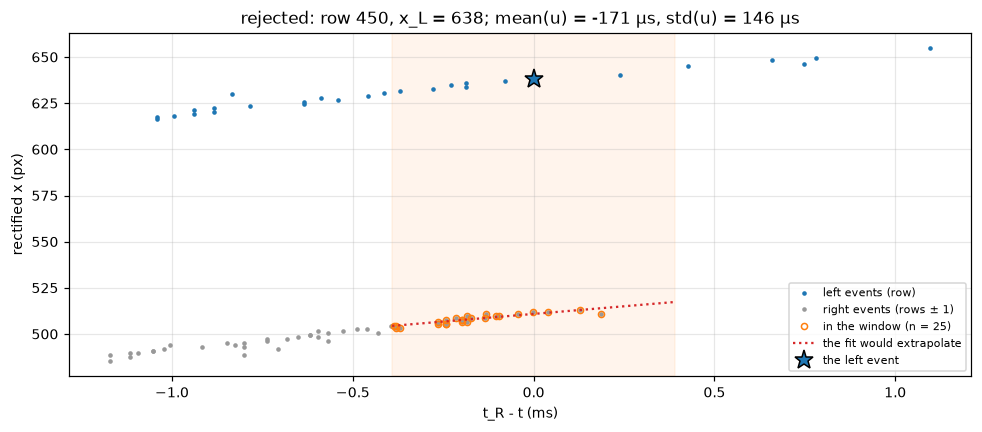

In [14]:
cand = np.where(kL & (status == 2))[0]
if cand.size:
    nb = n_fit[cand]
    ir = cand[np.argmax(nb)]
    tq2, xq2 = L.t[ir], L.x[ir]
    win2 = kR & (np.abs(R.t - tq2) <= tau_us)
    u2 = (R.t[win2] - tq2).astype(float)
    fig, ax = plt.subplots(figsize=(9, 4))
    near_L = kL & (np.abs(L.t - tq2) <= 3 * tau_us)
    near_R = kR & (np.abs(R.t - tq2) <= 3 * tau_us)
    ax.plot((L.t[near_L] - tq2) / 1e3, L.x[near_L], ".", ms=4, color=CAM_COLORS["left"], label="left events (row)")
    ax.plot((R.t[near_R] - tq2) / 1e3, R.x[near_R], ".", ms=4, color="0.6", label="right events (rows ± 1)")
    ax.plot(u2 / 1e3, R.x[win2], "o", ms=4, mfc="none", color=CAM_COLORS["right"],
            label=f"in the window (n = {win2.sum()})")
    ax.axvspan(-tau_us / 1e3, tau_us / 1e3, color=CAM_COLORS["right"], alpha=0.08)
    bb, aa = np.polyfit(u2, R.x[win2], 1)
    uu = np.linspace(-tau_us, tau_us, 10)
    ax.plot(uu / 1e3, aa + bb * uu, ":", color="tab:red", lw=1.5, label="the fit would extrapolate")
    ax.plot(0, xq2, "*", color=CAM_COLORS["left"], ms=13, mec="k", label="the left event")
    ax.set_xlabel("t_R - t (ms)"); ax.set_ylabel("rectified x (px)")
    ax.set_title(f"rejected: row {ROW}, x_L = {xq2:.0f}; mean(u) = {u2.mean():.0f} µs, std(u) = {u2.std():.0f} µs")
    ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()

Here the right stripe on these rows ends shortly after t: in the right image the stripe has reached the edge of the
object. All window events are earlier than t, and a line through them would extrapolate past the end of the
segment.

Where the left events end up, over the whole image (right: zoom on the stem of the far object, between the two near
objects):

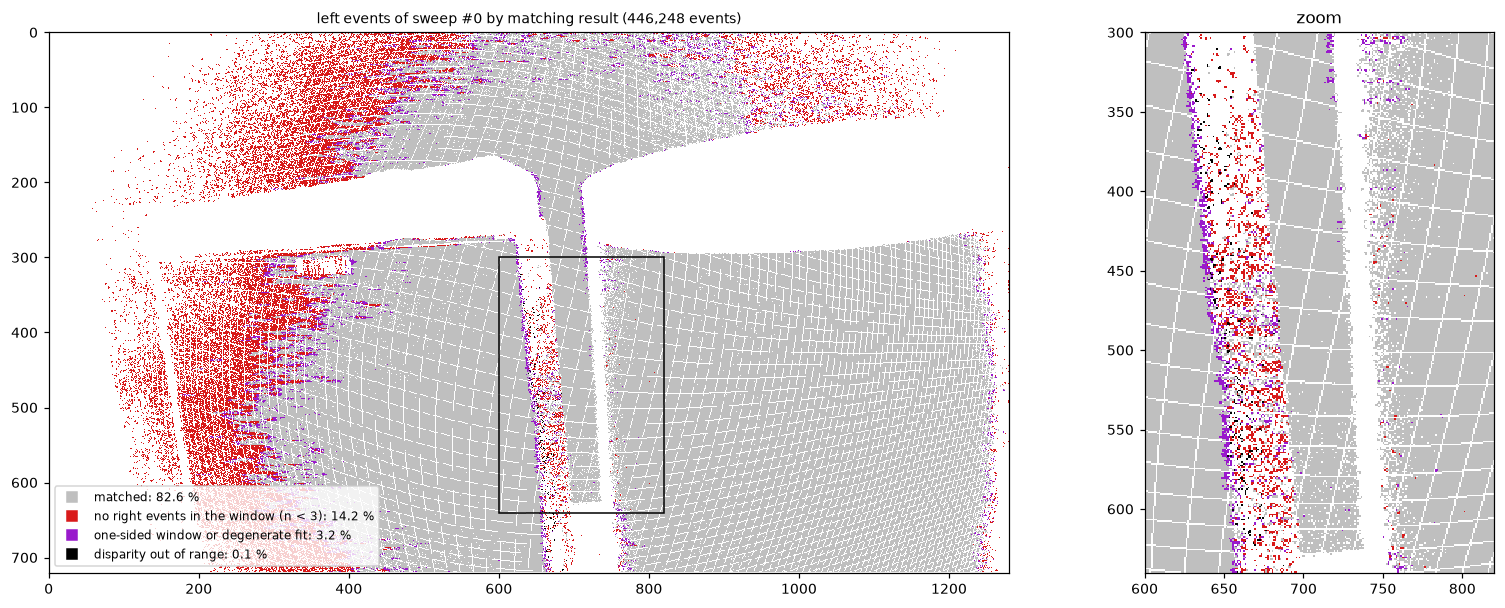

| Left image x | Left events | Right events (same scene band) | Right / left | Left events with n < 3 |
|---|---|---|---|---|
| 0–160 | 4k | 0k | 0.00 | 100 % |
| 160–320 | 40k | 1k | 0.03 | 78 % |
| 320–480 | 75k | 21k | 0.28 | 23 % |
| 480–640 | 85k | 57k | 0.67 | 2 % |
| 640–800 | 68k | 48k | 0.72 | 4 % |
| 800–960 | 71k | 66k | 0.93 | 2 % |
| 960–1120 | 60k | 59k | 0.99 | 6 % |
| 1120–1280 | 43k | 40k | 0.92 | 3 % |

In [15]:
names = ["matched", "no right events in the window (n < 3)", "one-sided window or degenerate fit",
         "disparity out of range"]
colors = np.array([[0.75, 0.75, 0.75], [0.85, 0.1, 0.1], [0.6, 0.1, 0.8], [0.0, 0.0, 0.0]])
img = np.ones((H, W, 3))
xi = np.clip(np.rint(L.x).astype(int), 0, W - 1)
for s in (0, 1, 2, 3):
    k = status == s
    img[L.row[k], xi[k]] = colors[s]
ZOOM = (600, 820, 300, 640)  # x0, x1, row0, row1
fig, axs = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.8, 1]})
axs[0].imshow(img, interpolation="nearest")
axs[0].add_patch(Rectangle((ZOOM[0], ZOOM[2]), ZOOM[1] - ZOOM[0], ZOOM[3] - ZOOM[2], fill=False, color="k", lw=1))
for s in range(4):
    axs[0].plot([], [], "s", color=colors[s], label=f"{names[s]}: {np.mean(status == s) * 100:.1f} %")
img_axes(axs[0], f"left events of sweep #{SW} by matching result ({L.t.size:,} events)")
axs[0].legend(fontsize=8, loc="lower left")
axs[1].imshow(img[ZOOM[2]:ZOOM[3], ZOOM[0]:ZOOM[1]], interpolation="nearest",
              extent=(ZOOM[0], ZOOM[1], ZOOM[3], ZOOM[2]))
axs[1].set_title("zoom"); axs[1].grid(False)
plt.tight_layout(); plt.show()

# Unmatched left events versus the density of the right camera's stripe, per 160 px column band of the left image
d_med = np.median(d_all[matched])
bands = np.arange(0, W + 1, 160)
rows = []
for b0, b1 in zip(bands[:-1], bands[1:]):
    kl = (L.x >= b0) & (L.x < b1)
    kr = (R.x >= b0 - d_med) & (R.x < b1 - d_med)  # The same scene band in the right image (shifted by ~d)
    if kl.sum() > 1000:
        rows.append([f"{b0}–{b1}", f"{kl.sum() / 1e3:.0f}k", f"{kr.sum() / 1e3:.0f}k",
                     f"{kr.sum() / kl.sum():.2f}", f"{np.mean(status[kl] == 1) * 100:.0f} %"])
md_table(["Left image x", "Left events", "Right events (same scene band)", "Right / left",
          "Left events with n < 3"], rows)

**82–83 % of the left events are matched.** The unmatched ones have three causes:

* **The right camera barely sees the stripe on the left of the scene** (most of the red). The table compares, for
  the same part of the scene, the events each camera keeps: left of x ≈ 450, the right camera has 0–30 % of the
  left camera's events, and most windows hold fewer than 3. The arrival maps of section 4 show the same. This
  is a signal problem, not a matching problem: the light that reaches the right camera from that part of the scene is
  weaker (the surface orientation, a sensitivity or bias difference between the cameras, or something partly
  blocking the right camera's view on that side). Worth checking on the hardware, since it costs ~14 % of the data.
* **Surfaces seen by one camera only** (zoom): the narrow strip between the board and the stem of the far object is
  seen by the left camera, while the right camera's map has a gap there. This is occlusion (t2 in the sketch):
  left events without a right stripe at their time.
* **Stripe ends** (purple): one-sided windows along the edges of surfaces, where the right stripe starts or ends
  inside the window.

In all three cases method C gives **no** value instead of a wrong one.

### 5.4 Implementation

`local_fit` processes all left events at once. The right events are sorted by (row, t) and the prefix sums of
1, t, x, t² and t·x are computed once. For each left event and each of the 2h + 1 rows, two binary searches
(`np.searchsorted`) find the window, and the window sums are differences of prefix sums. That is
O((N_L (2h+1) + N_R) log N_R), with no Python loop over events.

In [16]:
t_ = time.perf_counter()
row_m, x_m, d_m = sd.match_time(L, R, tau_us, dp)
t_match = time.perf_counter() - t_
print(f"match_time: {L.t.size:,} left events against {R.t.size:,} right events in {t_match:.2f} s "
      f"-> {d_m.size:,} disparities (same as above: {np.array_equal(d_m, d_all[matched])})")

match_time: 446,248 left events against 293,315 right events in 0.42 s -> 368,402 disparities (same as above: True)


### 5.5 Precision of a single match

On a flat surface, the disparity is an affine function of (x, row): d = c0 + c1·x + c2·row. Fitting it robustly to
the matched events of a patch of the flat board on the left leaves the per-event noise. (The right-hand object is
curved, see the top view in section 7.)

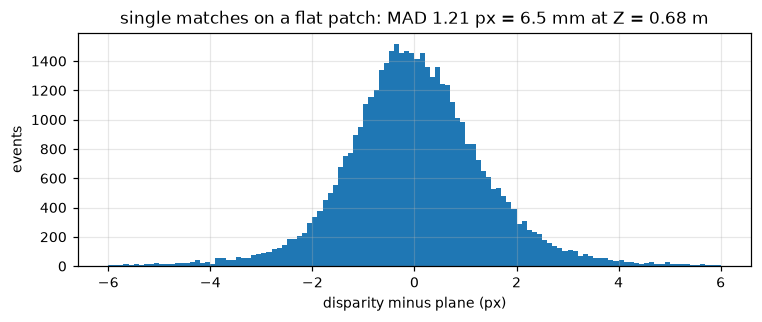

44,116 matches in the patch; beyond ±3 px: 4.8 %


In [17]:
FLAT = (450, 630, 330, 600)  # x0, x1, row0, row1 of a flat patch on the left board (rectified left image)


def plane_resid(x, row, d, iters=5, thr=3.0):
    A = np.stack([np.ones_like(x), x, row], 1)
    keep = np.ones(x.size, bool)
    for _ in range(iters):
        coef = np.linalg.lstsq(A[keep], d[keep], rcond=None)[0]
        r = d - A @ coef
        keep = np.abs(r) < thr
    return r, coef


k = (x_m >= FLAT[0]) & (x_m < FLAT[1]) & (row_m >= FLAT[2]) & (row_m < FLAT[3])
res_ev, coef_flat = plane_resid(x_m[k], row_m[k].astype(float), d_m[k])
mad_ev = 1.4826 * np.median(np.abs(res_ev))
z_flat = fB / np.median(d_m[k])
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(res_ev, bins=np.linspace(-6, 6, 121), color=CAM_COLORS["left"])
ax.set_xlabel("disparity minus plane (px)"); ax.set_ylabel("events")
ax.set_title(f"single matches on a flat patch: MAD {mad_ev:.2f} px = {mad_ev * z_flat ** 2 / fB * 1e3:.1f} mm "
             f"at Z = {z_flat:.2f} m")
plt.tight_layout(); plt.show()
print(f"{k.sum():,} matches in the patch; beyond ±3 px: {np.mean(np.abs(res_ev) > 3) * 100:.1f} %")

## 6. Depth image

**Rasterise.** Each matched left event puts its disparity on its rectified pixel (round(x), row); the few pixels that
get two values take their mean. The result is sparse (the rectification grid lines, unlit pixels) and noisy (the
per-event scatter above, plus a few wrong matches).

**Robust aggregation** (`robust_aggregate`, k = 7, max_dev = 1.5 px, min_support = 8). For every pixel, over its
7 × 7 window:

1. m = median of the valid disparities in the window;
2. the output is the **mean of the values within ±1.5 px of m**;
3. it is kept only if ≥ 8 values agree. Pixels without their own value get one too, if the window agrees, which
   fills the grid lines and small holes.

The median picks the majority surface inside the window; the ±1.5 px band then drops values from the other side of
an edge and wrong matches. Averaging the ≥ 8 inliers reduces the noise by roughly √8. A plain mean would mix the two
surfaces at an edge.

A 7 × 7 window on the edge between two objects:

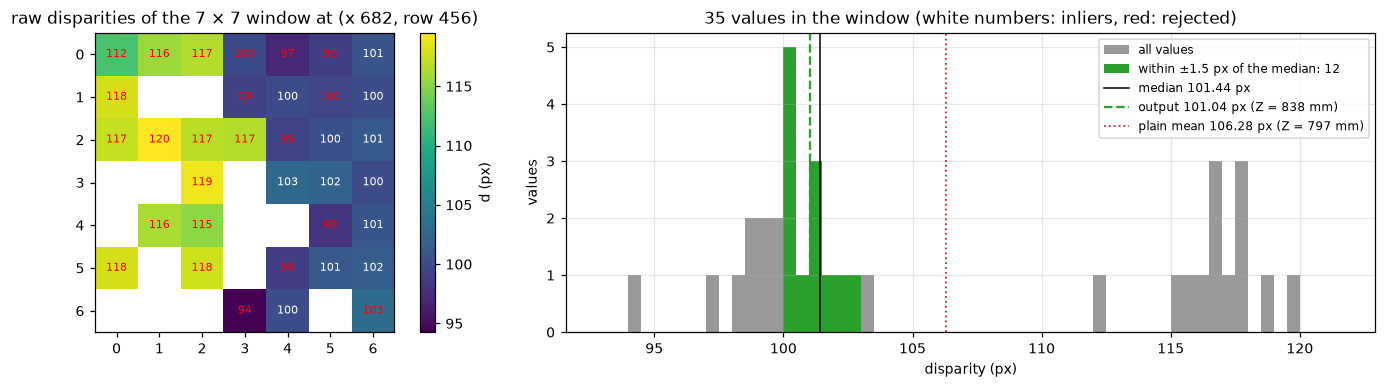

In [18]:
raw = sd.rasterise(row_m, x_m, d_m, W, H)
disp, support = sd.robust_aggregate(raw, dp.agg_k, dp.agg_max_dev_px, dp.agg_min_support)
r_ = dp.agg_k // 2

# Find a window that straddles an edge: its values split into two tight groups (each >= 10 values, interquartile
# range < 2.5 px) separated by a gap of > 6 px. Searched on rows ROW +- 30.
cands = []
for yc in range(ROW - 30, ROW + 31, 2):
    for xc in range(r_, W - r_):
        v = raw[yc - r_:yc + r_ + 1, xc - r_:xc + r_ + 1].ravel()
        v = np.sort(v[np.isfinite(v)])
        if v.size < 25:
            continue
        g = np.diff(v)
        j = int(np.argmax(g))
        lo_, hi_ = v[:j + 1], v[j + 1:]
        if g[j] < 6 or min(lo_.size, hi_.size) < 10:
            continue
        if max(np.subtract(*np.percentile(lo_, [75, 25])), np.subtract(*np.percentile(hi_, [75, 25]))) > 2.5:
            continue
        cands.append((min(lo_.size, hi_.size), yc, xc))
_, ROW_AG, XC = max(cands)
v = raw[ROW_AG - r_:ROW_AG + r_ + 1, XC - r_:XC + r_ + 1]
vals = v[np.isfinite(v)]
m = np.median(vals)
inl = np.abs(vals - m) <= dp.agg_max_dev_px

fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
im = axs[0].imshow(v, cmap="viridis", interpolation="nearest")
axs[0].set_title(f"raw disparities of the 7 × 7 window at (x {XC}, row {ROW_AG})"); axs[0].grid(False)
for (yy, xx) in zip(*np.nonzero(np.isfinite(v))):
    axs[0].text(xx, yy, f"{v[yy, xx]:.0f}", ha="center", va="center", fontsize=7,
                color="w" if abs(v[yy, xx] - m) <= dp.agg_max_dev_px else "r")
plt.colorbar(im, ax=axs[0], label="d (px)")
bins = np.arange(np.floor(vals.min()) - 1, np.ceil(vals.max()) + 2, 0.5)
axs[1].hist(vals, bins=bins, color="0.6", label="all values")
axs[1].hist(vals[inl], bins=bins, color="tab:green", label=f"within ±{dp.agg_max_dev_px} px of the median: {inl.sum()}")
axs[1].axvline(m, color="k", lw=1, label=f"median {m:.2f} px")
axs[1].axvline(vals[inl].mean(), color="tab:green", lw=1.5, ls="--",
               label=f"output {vals[inl].mean():.2f} px (Z = {fB / vals[inl].mean() * 1e3:.0f} mm)")
axs[1].axvline(vals.mean(), color="tab:red", lw=1.2, ls=":",
               label=f"plain mean {vals.mean():.2f} px (Z = {fB / vals.mean() * 1e3:.0f} mm)")
axs[1].set_xlabel("disparity (px)"); axs[1].set_ylabel("values"); axs[1].legend(fontsize=8)
axs[1].set_title(f"{vals.size} values in the window (white numbers: inliers, red: rejected)")
plt.tight_layout(); plt.show()

The window holds two surfaces: the far object's stem and the edge of the board in front of it. The median falls in
the larger group; the values of the other surface lie more than 1.5 px away and are dropped. The output belongs to
one surface. The plain mean lies between the two groups: a depth where there is no surface.

Around the same place: raw, plain 7 × 7 mean, and robust aggregation, as depth, with the profile along the row
underneath.

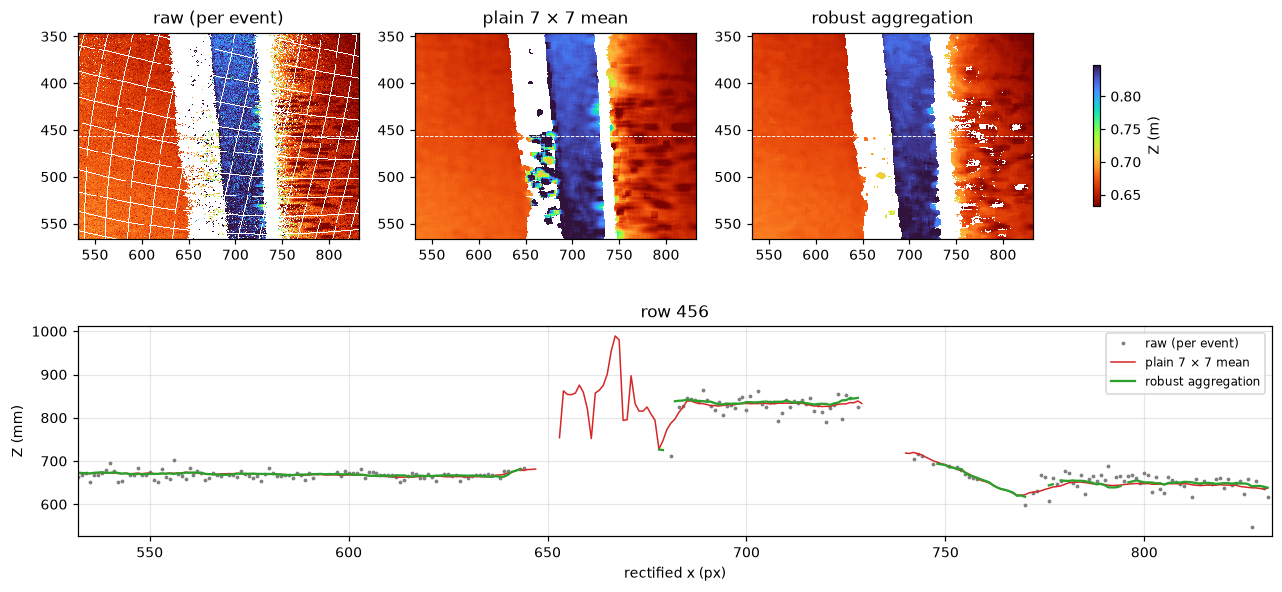

In [19]:
def nan_box_mean(img, k):
    r = k // 2
    pad = np.pad(img, r, constant_values=np.nan)
    win = np.lib.stride_tricks.sliding_window_view(pad, (k, k))
    valid = np.isfinite(win)
    n = valid.sum((-1, -2))
    s = np.where(valid, win, 0).sum((-1, -2))
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(n >= dp.agg_min_support, s / np.maximum(n, 1), np.nan)


cx0, cx1 = max(0, XC - 150), min(W, XC + 150)
cy0, cy1 = max(0, ROW_AG - 110), min(H, ROW_AG + 110)
crop = {"raw (per event)": raw[cy0:cy1, cx0:cx1], "plain 7 × 7 mean": nan_box_mean(raw[cy0:cy1, cx0:cx1], dp.agg_k),
        "robust aggregation": disp[cy0:cy1, cx0:cx1]}
zc = fB / disp[cy0:cy1, cx0:cx1]
zlo, zhi = np.nanpercentile(zc, [1, 99])
fig = plt.figure(figsize=(14, 6.4))
gs = fig.add_gridspec(2, 3, height_ratios=[1.35, 1])
for j, (name, img_) in enumerate(crop.items()):
    ax = fig.add_subplot(gs[0, j])
    with np.errstate(divide="ignore", invalid="ignore"):
        im = ax.imshow(fB / img_, cmap="turbo_r", vmin=zlo, vmax=zhi, interpolation="nearest",
                       extent=(cx0, cx1, cy1, cy0))
    ax.axhline(ROW_AG, color="w", lw=0.6, ls="--"); ax.set_title(name); ax.grid(False)
plt.colorbar(im, ax=fig.axes, shrink=0.5, label="Z (m)", location="right")
ax = fig.add_subplot(gs[1, :])
xs = np.arange(cx0, cx1)
with np.errstate(divide="ignore", invalid="ignore"):
    ax.plot(xs, fB / raw[ROW_AG, cx0:cx1] * 1e3, ".", ms=3, color="0.5", label="raw (per event)")
    ax.plot(xs, fB / crop["plain 7 × 7 mean"][ROW_AG - cy0] * 1e3, "-", color="tab:red", lw=1, label="plain 7 × 7 mean")
    ax.plot(xs, fB / disp[ROW_AG, cx0:cx1] * 1e3, "-", color="tab:green", lw=1.5, label="robust aggregation")
ax.set_xlabel("rectified x (px)"); ax.set_ylabel("Z (mm)"); ax.set_title(f"row {ROW_AG}"); ax.legend(fontsize=8)
ax.set_xlim(cx0, cx1)
plt.show()

In the strip between the board and the stem (x ≈ 650–680), the raw values are sparse and scattered (the occluded
strip of section 5.3). The plain mean turns them into invented depths of up to ~1 m, and it rounds off the edges of
the stem. The robust aggregation leaves the strip empty, because no 8 values agree, and keeps both surfaces flat up
to their edges. The slope at x ≈ 740–770 is real: the curved object bends away there.

The full depth image of sweep #0, Z = f B / d:

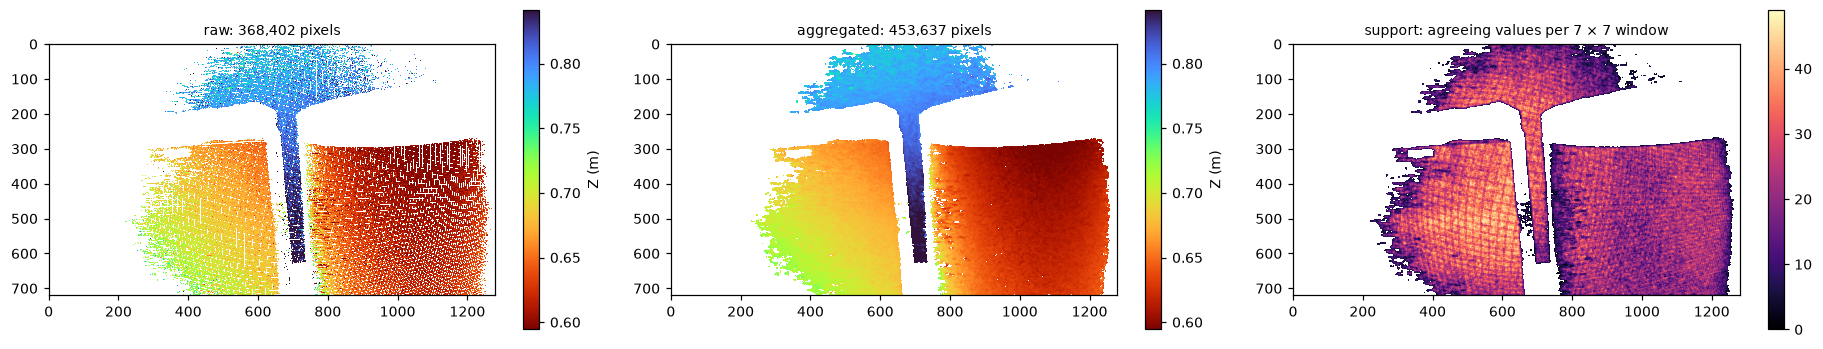

flat patch: per-event MAD 1.21 px -> aggregated MAD 0.34 px (1.8 mm at 0.68 m)


In [20]:
depth = fB / disp
fig, axs = plt.subplots(1, 3, figsize=(17, 3.9))
with np.errstate(divide="ignore", invalid="ignore"):
    im0 = axs[0].imshow(fB / raw, cmap="turbo_r", vmin=np.nanpercentile(depth, 1), vmax=np.nanpercentile(depth, 99),
                        interpolation="nearest")
im1 = axs[1].imshow(depth, cmap="turbo_r", vmin=np.nanpercentile(depth, 1), vmax=np.nanpercentile(depth, 99),
                    interpolation="nearest")
im2 = axs[2].imshow(np.where(support > 0, support, np.nan), cmap="magma", vmin=0, vmax=dp.agg_k ** 2,
                    interpolation="nearest")
img_axes(axs[0], f"raw: {np.isfinite(raw).sum():,} pixels")
img_axes(axs[1], f"aggregated: {np.isfinite(disp).sum():,} pixels")
img_axes(axs[2], "support: agreeing values per 7 × 7 window")
plt.colorbar(im0, ax=axs[0], shrink=0.8, label="Z (m)"); plt.colorbar(im1, ax=axs[1], shrink=0.8, label="Z (m)")
plt.colorbar(im2, ax=axs[2], shrink=0.8)
plt.tight_layout(); plt.show()

k = (np.arange(W)[None, :] >= FLAT[0]) & (np.arange(W)[None, :] < FLAT[1]) & \
    (np.arange(H)[:, None] >= FLAT[2]) & (np.arange(H)[:, None] < FLAT[3]) & np.isfinite(disp)
yy, xx = np.nonzero(k)
res_ag, _ = plane_resid(xx.astype(float), yy.astype(float), disp[k].astype(float))
mad_ag = 1.4826 * np.median(np.abs(res_ag))
print(f"flat patch: per-event MAD {mad_ev:.2f} px -> aggregated MAD {mad_ag:.2f} px "
      f"({mad_ag * z_flat ** 2 / fB * 1e3:.1f} mm at {z_flat:.2f} m)")

## 7. Point cloud

Every pixel of the depth image is back-projected into the rectified left camera frame (x right, y down, z forward,
metres): X = (x − c_x) Z / f, Y = (row − c_y) Z / f. `process_sweep` runs sections 4–6 in one call, and
`save_result` writes the depth image (npz), the coloured point cloud (PLY) and the statistics (JSON).

process_sweep gives the same depth image: True | 2.3 s for the sweep


written: sweep00_depth.npz sweep00_cloud.ply sweep00_info.json sweep00_depth_mm.png in D:\Projects\delidar\EVK4Calibration\05_experiments\output\end_to_end\rec_20261116_162206


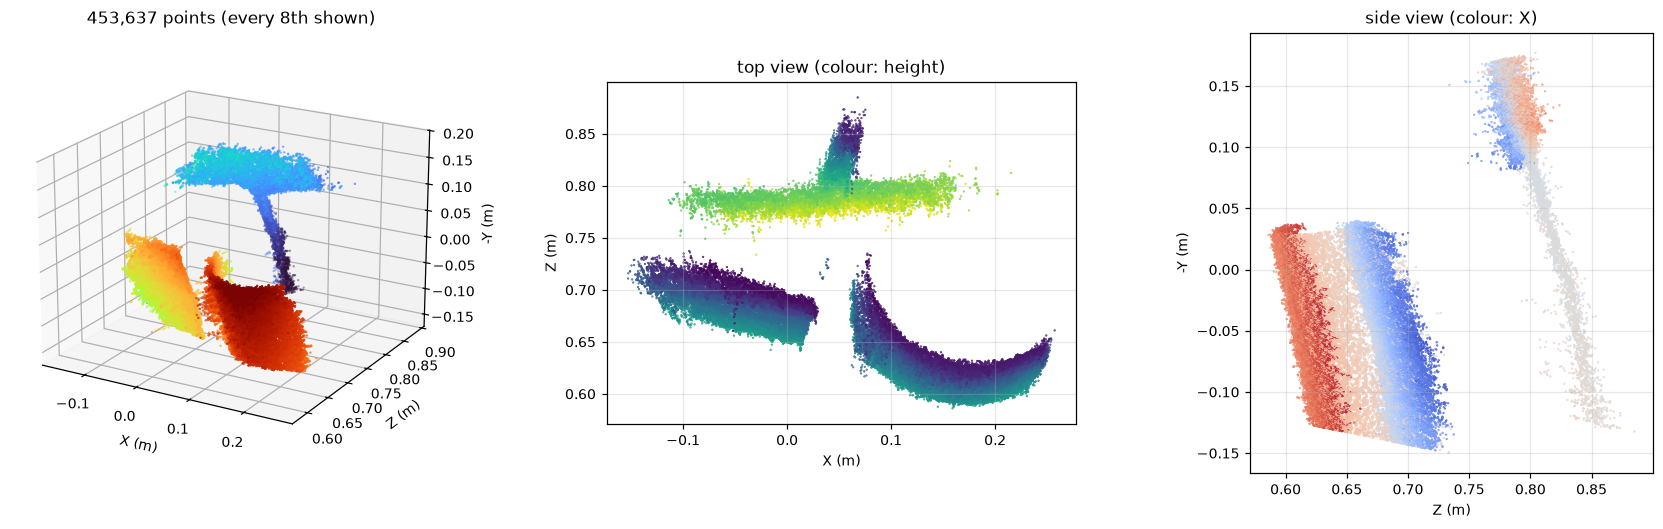

In [21]:
res0 = sd.process_sweep(readers, rig, t0, t1, dp)
print("process_sweep gives the same depth image:", np.array_equal(res0.disp, disp, equal_nan=True),
      f"| {res0.stats['total_s']:.1f} s for the sweep")
rig_like = sd.rig_dict(rig)
pts, (py, px) = sd.cloud_from_result(res0, rig_like)
files0 = sd.save_result(res0, rig_like, OUT_DIR / f"sweep{SW:02d}")
sd.write_depth_png16(OUT_DIR / f"sweep{SW:02d}_depth_mm.png", res0.depth)
print("written:", *[Path(f).name for f in files0.values()], f"sweep{SW:02d}_depth_mm.png", "in", OUT_DIR)

sub = pts[::8]
zlo, zhi = np.percentile(pts[:, 2], [1, 99])
fig = plt.figure(figsize=(16, 5.2))
ax = fig.add_subplot(1, 3, 1, projection="3d")
ax.scatter(sub[:, 0], sub[:, 2], -sub[:, 1], c=sub[:, 2], cmap="turbo_r", vmin=zlo, vmax=zhi, s=0.3)
ax.set_xlabel("X (m)"); ax.set_ylabel("Z (m)"); ax.set_zlabel("-Y (m)"); ax.view_init(elev=20, azim=-60)
ax.set_title(f"{len(pts):,} points (every 8th shown)")
ax = fig.add_subplot(1, 3, 2)
ax.scatter(sub[:, 0], sub[:, 2], c=-sub[:, 1], cmap="viridis", s=0.2)
ax.set_xlabel("X (m)"); ax.set_ylabel("Z (m)"); ax.set_title("top view (colour: height)"); ax.set_aspect("equal")
ax = fig.add_subplot(1, 3, 3)
ax.scatter(sub[:, 2], -sub[:, 1], c=sub[:, 0], cmap="coolwarm", s=0.2)
ax.set_xlabel("Z (m)"); ax.set_ylabel("-Y (m)"); ax.set_title("side view (colour: X)"); ax.set_aspect("equal")
fig.subplots_adjust(left=0.02, right=0.98, wspace=0.3)
plt.show()

Interactive view (Open3D, starts from the camera's viewpoint):

```
python 06_stripe_depth/cloud_viewer.py 05_experiments/output/end_to_end/rec_20261116_162206/sweep00_cloud.ply
```

## 8. All sweeps: repeatability and the direction of the sweep

The six sweeps alternate direction. Without ground truth, the agreement between sweeps measures precision: sweeps in
the **same** direction should give the same depth up to noise. A difference between **opposite** directions shows a
systematic, direction-dependent error. On the flat wall of the earlier recordings it was about ±1.2 px
(`stripe_correspondence.ipynb`, section 6).

In [22]:
results = []
rows = []
for k, (a, b) in enumerate(sweeps):
    r = res0 if k == SW else sd.process_sweep(readers, rig, a, b, dp)
    results.append(r)
    s = r.stats
    sd.save_result(r, rig_like, OUT_DIR / f"sweep{k:02d}")
    sd.write_depth_png16(OUT_DIR / f"sweep{k:02d}_depth_mm.png", r.depth)
    rows.append([f"#{k}", "→" if s["direction"] > 0 else "←", f"{s['speed_px_ms']:.1f}", f"{s['cross_ms']:.0f}",
                 f"{s['tau_us']:.0f}", f"{s['first_events']['left'] / 1e3:.0f}k / {s['first_events']['right'] / 1e3:.0f}k",
                 f"{s['matched'] / s['first_events']['left'] * 100:.0f} %", f"{s['depth_px'] / 1e3:.0f}k",
                 f"{s['z_median_m']:.3f}", f"{s['total_s']:.1f}"])
md_table(["Sweep", "Dir.", "Speed (px/ms)", "Cross time (ms)", "τ (µs)", "Kept events L / R", "Left events matched",
          "Depth pixels", "Median Z (m)", "Processing (s)"], rows)

| Sweep | Dir. | Speed (px/ms) | Cross time (ms) | τ (µs) | Kept events L / R | Left events matched | Depth pixels | Median Z (m) | Processing (s) |
|---|---|---|---|---|---|---|---|---|---|
| #0 | → | 20.4 | 63 | 391 | 446k / 293k | 83 % | 454k | 0.669 | 2.3 |
| #1 | ← | 22.2 | 58 | 360 | 433k / 293k | 84 % | 459k | 0.681 | 2.3 |
| #2 | → | 20.5 | 62 | 390 | 445k / 293k | 83 % | 454k | 0.669 | 2.4 |
| #3 | ← | 22.3 | 57 | 358 | 434k / 293k | 84 % | 458k | 0.682 | 2.2 |
| #4 | → | 20.3 | 63 | 393 | 443k / 292k | 83 % | 453k | 0.669 | 2.3 |
| #5 | ← | 22.3 | 57 | 358 | 436k / 297k | 85 % | 466k | 0.682 | 2.2 |

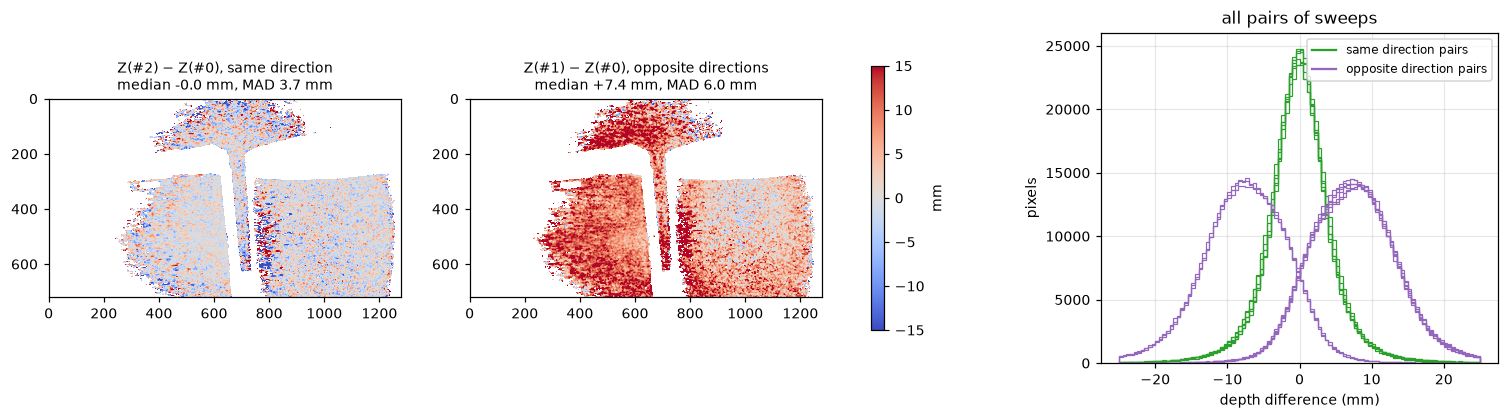

| Pairs | Number | Mean absolute median difference (mm) | Mean MAD of the difference (mm) |
|---|---|---|---|
| same direction | 6 | 0.1 | 3.8 |
| opposite directions | 9 | 7.4 | 6.0 |

In [23]:
Z = np.stack([r.depth for r in results]) * 1e3  # mm
dirs = np.array([r.direction for r in results])
same = [(i, j) for i in range(len(results)) for j in range(i + 1, len(results)) if dirs[i] == dirs[j]]
opp = [(i, j) for i in range(len(results)) for j in range(i + 1, len(results)) if dirs[i] != dirs[j]]


def diff_stats(i, j):
    dz = Z[j] - Z[i]
    v = dz[np.isfinite(dz)]
    return dz, np.median(v), 1.4826 * np.median(np.abs(v - np.median(v))), v.size


i_s, j_s = same[0]
i_o, j_o = (0, 1)
fig, axs = plt.subplots(1, 3, figsize=(17, 3.9), gridspec_kw={"width_ratios": [1, 1, 0.9]})
for ax, (i, j), lab in ((axs[0], (i_s, j_s), "same direction"), (axs[1], (i_o, j_o), "opposite directions")):
    dz, mdz, sdz, n = diff_stats(i, j)
    im = ax.imshow(dz, cmap="coolwarm", vmin=-15, vmax=15, interpolation="nearest")
    img_axes(ax, f"Z(#{j}) − Z(#{i}), {lab}\nmedian {mdz:+.1f} mm, MAD {sdz:.1f} mm")
plt.colorbar(im, ax=axs[:2], shrink=0.8, label="mm")
for (i, j), col in [(p_, "tab:green") for p_ in same] + [(p_, "tab:purple") for p_ in opp]:
    dz, *_ = diff_stats(i, j)
    v = dz[np.isfinite(dz)]
    axs[2].hist(v, bins=np.linspace(-25, 25, 101), histtype="step", color=col, lw=0.8)
axs[2].plot([], [], color="tab:green", label="same direction pairs"); axs[2].plot([], [], color="tab:purple",
                                                                                 label="opposite direction pairs")
axs[2].set_xlabel("depth difference (mm)"); axs[2].set_ylabel("pixels"); axs[2].legend(fontsize=8)
axs[2].set_title("all pairs of sweeps")
plt.show()

rows = []
for lab, pairs in (("same direction", same), ("opposite directions", opp)):
    st = [diff_stats(i, j) for i, j in pairs]
    rows.append([lab, len(pairs), f"{np.mean([abs(s_[1]) for s_ in st]):.1f}", f"{np.mean([s_[2] for s_ in st]):.1f}"])
md_table(["Pairs", "Number", "Mean absolute median difference (mm)", "Mean MAD of the difference (mm)"], rows)

**Same direction**: the difference is centred on zero (median ≤ 0.1 mm), with a MAD of ~3.8 mm per pixel pair, so
~2.7 mm per depth image. That is the repeatability of one sweep. **Opposite directions**: the difference is offset
by ~7 mm, i.e. each direction is off by about ±3.7 mm from their mean, and the offset is not the same everywhere.
This direction-dependent bias is the main systematic error left.

**Depth per region** in each sweep (median Z in the boxes drawn on the depth image):

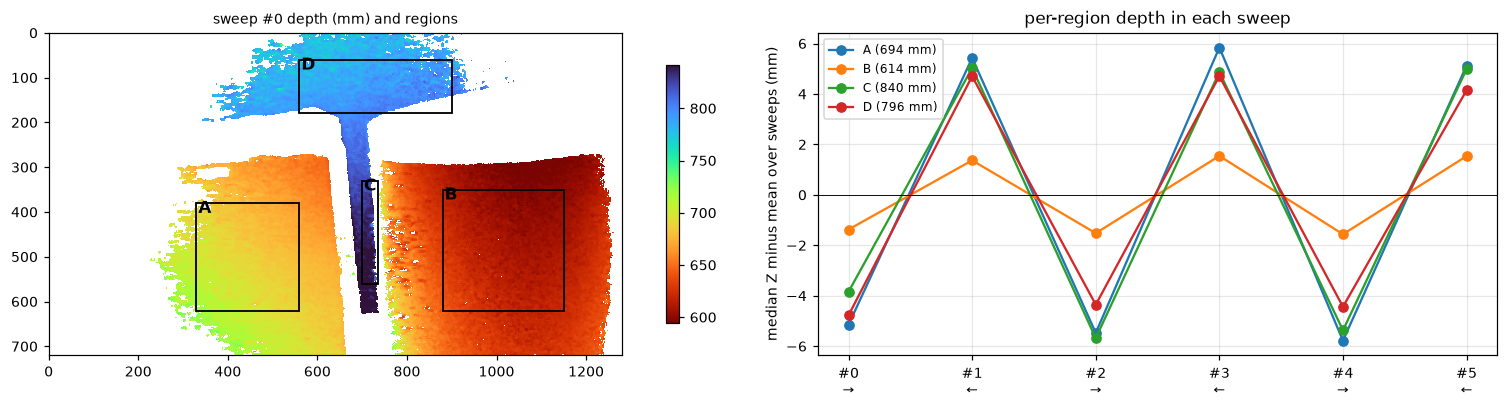

| Region | Mean median Z (mm) | #0 (→) | #1 (←) | #2 (→) | #3 (←) | #4 (→) | #5 (←) | Direction offset |
|---|---|---|---|---|---|---|---|---|
| A | 694 | -5.1 | +5.4 | -5.5 | +5.8 | -5.8 | +5.1 | ±5.5 mm = ±0.96 px |
| B | 614 | -1.4 | +1.4 | -1.5 | +1.5 | -1.6 | +1.5 | ±1.5 mm = ±0.33 px |
| C | 840 | -3.8 | +5.0 | -5.7 | +4.9 | -5.4 | +5.0 | ±5.0 mm = ±0.60 px |
| D | 796 | -4.8 | +4.7 | -4.4 | +4.7 | -4.4 | +4.1 | ±4.5 mm = ±0.60 px |

In [24]:
ROIS = {"A": (330, 560, 380, 620), "B": (880, 1150, 350, 620), "C": (700, 735, 330, 560), "D": (560, 900, 60, 180)}
fig, axs = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
im = axs[0].imshow(Z[0], cmap="turbo_r", vmin=np.nanpercentile(Z[0], 1), vmax=np.nanpercentile(Z[0], 99),
                   interpolation="nearest")
for name, (x0_, x1_, y0_, y1_) in ROIS.items():
    axs[0].add_patch(Rectangle((x0_, y0_), x1_ - x0_, y1_ - y0_, fill=False, color="k", lw=1.2))
    axs[0].text(x0_ + 4, y0_ + 22, name, fontsize=11, weight="bold")
img_axes(axs[0], "sweep #0 depth (mm) and regions"); plt.colorbar(im, ax=axs[0], shrink=0.8)
rows = []
for name, (x0_, x1_, y0_, y1_) in ROIS.items():
    med_k = np.array([np.nanmedian(Z[k][y0_:y1_, x0_:x1_]) for k in range(len(results))])
    axs[1].plot(range(len(results)), med_k - med_k.mean(), "o-", label=f"{name} ({med_k.mean():.0f} mm)")
    half = (med_k[dirs < 0].mean() - med_k[dirs > 0].mean()) / 2  # Half the difference between the directions
    rows.append([name, f"{med_k.mean():.0f}"] + [f"{v_ - med_k.mean():+.1f}" for v_ in med_k] +
                [f"±{abs(half):.1f} mm = ±{abs(half) / (med_k.mean() ** 2 / (fB * 1e3)):.2f} px"])
axs[1].set_xticks(range(len(results)), [f"#{k}\n{'→' if d_ > 0 else '←'}" for k, d_ in enumerate(dirs)])
axs[1].axhline(0, color="k", lw=0.6); axs[1].set_ylabel("median Z minus mean over sweeps (mm)")
axs[1].legend(fontsize=8); axs[1].set_title("per-region depth in each sweep")
plt.tight_layout(); plt.show()
md_table(["Region", "Mean median Z (mm)"] + [f"#{k} ({'→' if d_ > 0 else '←'})" for k, d_ in enumerate(dirs)] +
         ["Direction offset"], rows)

Every region alternates with the direction of the sweep, by the same amount in every sweep of a direction: the
offset is systematic, not noise. Left-to-right sweeps (→) measure the scene nearer, right-to-left sweeps (←) farther.
In disparity it is ±0.3 to ±1 px and depends on the surface: smallest on the curved object (B), largest on the board
(A), where the right camera's stripe is weakest.

A plausible explanation: the right camera fires slightly *later* than the left one when the stripe arrives
(event-camera latency grows as the light gets weaker). With the stripe moving at v px/ms, a delay δ shifts the
fitted right position by v·δ against the direction of motion: the disparity comes out too large for → sweeps and
too small for ← sweeps, which is the sign observed. ±1 px at 22 px/ms is ~45 µs. Ways to remove it:

* average one → and one ← sweep (the offsets cancel, at the cost of half the frame rate);
* measure the offset per direction once (for example on a flat target) and subtract it from the disparity;
* equalise the two cameras' response (biases, aperture, focus) so that both fire at the same point of the stripe's
  brightness profile.

## 9. Summary

| Step | What it does | Key parameters (defaults) |
|---|---|---|
| Rectification | per-pixel LUT from the step 1 + 2 calibration; x sub-pixel, row rounded | — |
| Sweep segmentation | left ON events per ms above median + 6 σ; merge gaps < 20 ms; pad 5 ms | `SweepParams` |
| Stripe arrival | first ON event per pixel that has ≥ 2 of 8 neighbours active within ±300 µs | `nb_min`, `nb_delta_us` |
| Stripe motion | median x per 0.5 ms → direction, speed; τ = 8 px / speed | `tau_px` |
| **Timestamp matching** | per left event: line fit x_R = a + b (t_R − t) over right events of rows ± 1 within ±τ; d = x_L − a; reject one-sided windows | `row_halfwidth`, `min_events`, `d_min`, `d_max` |
| Depth image | rasterise; 7 × 7 median, mean of values within ±1.5 px, ≥ 8 agreeing | `agg_k`, `agg_max_dev_px`, `agg_min_support` |
| Point cloud | back-projection in the rectified left frame; npz / PLY / 16-bit PNG | — |

What this recording shows:

* **Time is the correspondence.** With the shared clock and rectification, each left event has exactly one candidate
  on the right: where the right stripe is on the same row at the same time. No appearance matching and no search.
  It works with several objects at different depths, because the match is made per event, not per stripe.
* **Depth edges stay sharp.** The per-event matching never mixes two surfaces as long as the window does not straddle
  an edge, and the one-sided-window check rejects most of the cases where it does. The robust aggregation keeps each
  output pixel on one surface.
* **Occlusions and shadows give holes, not wrong depths.** Left events whose point the right camera cannot see find
  no right stripe at their time and are rejected. A laser shadow has no events at all. 83 % of the left events are
  matched; most of the rest is lost because the right camera hardly sees the stripe on the left of this scene.
* **Precision.** On the flat board (0.68 m), one match has a scatter (MAD) of 1.2 px (6.5 mm); after the 7 × 7
  aggregation, 0.34 px (1.8 mm). Sweeps in the same direction repeat to ~3.8 mm per pixel pair.
* **Systematic error.** Left-going and right-going sweeps differ by ±0.3–1 px (±1.5–5.5 mm here), depending on the
  surface. A timing difference between the two cameras' response to the stripe would explain it. Averaging both
  directions or a per-direction offset correction removes it.
* **Speed.** The stripe crosses the image in ~60 ms (> 10 depth images per second if the laser swept continuously).
  The Python implementation needs ~2 s per sweep (reading and filtering the events take most of it), so it is an
  offline reference, not yet real time.

Files written to `05_experiments/output/end_to_end/rec_20261116_162206/`: for each sweep, `sweepNN_depth.npz`
(all images, depth in m), `sweepNN_cloud.ply`, `sweepNN_info.json` and `sweepNN_depth_mm.png` (16-bit, mm, 0 = no
depth).

In [25]:
for rd in readers.values():
    rd.close()